# 03. EDA · 모든 변수 꼼꼼히 보기

**목표**: 변수 하나하나의 분포와 타깃(`box_off_num`, 관객수)과의 관계, 변수끼리의 관계를 확인하고 → **전처리 · 파생변수 아이디어**를 뽑는다.

| # | 내용 |
| --- | --- |
| 0 | 설정 · 데이터 로딩 |
| 1 | 데이터 개요 (타입 · 결측 · 고유값 · 중복) |
| 2 | 타깃 분석 (분포 · 로그 변환 · 대박 영화가 RMSE에 미치는 영향) |
| 3 | 결측치 (`dir_prev_bfnum`) |
| 4 | 수치형 변수 하나씩 |
| 5 | 범주형 변수 하나씩 |
| 6 | 날짜 (`release_time`) |
| 7 | 감독 · 제목 |
| 8 | 변수 간 관계 |
| 9 | train vs test 분포 비교 |
| 10 | 시사점 정리 |

> 평가 지표가 **원래 관객수 단위 RMSE**라서, 관객수가 큰 영화를 얼마나 잘 맞히는지가 점수를 좌우함 → 이 관점으로 계속 확인.

## 0. 설정 · 데이터 로딩

In [1]:
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

warnings.filterwarnings('ignore')

# 한글 폰트: 윈도우 'Malgun Gothic' / 맥 'AppleGothic' / 코랩은 나눔폰트 설치 필요
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid', font='Malgun Gothic', rc={'axes.unicode_minus': False})

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

DATA_DIR = '.'
train = pd.read_csv(os.path.join(DATA_DIR, 'movies_train.csv'))
test = pd.read_csv(os.path.join(DATA_DIR, 'movies_test.csv'))

TARGET = 'box_off_num'
NUM_COLS = ['time', 'dir_prev_bfnum', 'dir_prev_num', 'num_staff', 'num_actor']
CAT_COLS = ['distributor', 'genre', 'screening_rat']

# 관객수는 매우 치우쳐 있어서 관계를 볼 때는 로그 타깃을 같이 사용
train['log_target'] = np.log1p(train[TARGET])
print('train', train.shape, '| test', test.shape)

train (600, 13) | test (243, 11)


## 1. 데이터 개요

In [2]:
display(train.head())
display(test.head())

,title,distributor,genre,release_time,time,screening_rat,director,dir_prev_bfnum,dir_prev_num,num_staff,num_actor,box_off_num,log_target
0,개들의 전쟁,롯데엔터테인먼트,액션,2012-11-22,96,청소년 관람불가,조병옥,NaN,0,91,2,23398,10.060449
1,내부자들,(주)쇼박스,느와르,2015-11-19,130,청소년 관람불가,우민호,1161602.50,2,387,3,7072501,15.771725
2,은밀하게 위대하게,(주)쇼박스,액션,2013-06-05,123,15세 관람가,장철수,220775.25,4,343,4,6959083,15.755558
3,나는 공무원이다,(주)NEW,코미디,2012-07-12,101,전체 관람가,구자홍,23894.00,2,20,6,217866,12.291640
4,불량남녀,쇼박스(주)미디어플렉스,코미디,2010-11-04,108,15세 관람가,신근호,1.00,1,251,2,483387,13.088575


,title,distributor,genre,release_time,time,screening_rat,director,dir_prev_bfnum,dir_prev_num,num_staff,num_actor
0,용서는 없다,시네마서비스,느와르,2010-01-07,125,청소년 관람불가,김형준,3.005290e+05,2,304,3
1,아빠가 여자를 좋아해,(주)쇼박스,멜로/로맨스,2010-01-14,113,12세 관람가,이광재,3.427002e+05,4,275,3
2,하모니,CJ 엔터테인먼트,드라마,2010-01-28,115,12세 관람가,강대규,4.206611e+06,3,419,7
3,의형제,(주)쇼박스,액션,2010-02-04,116,15세 관람가,장훈,6.913420e+05,2,408,2
4,평행 이론,CJ 엔터테인먼트,공포,2010-02-18,110,15세 관람가,권호영,3.173800e+04,1,380,1


In [3]:
def overview(df):
    return pd.DataFrame({
        'dtype': df.dtypes.astype(str),
        '결측 수': df.isna().sum(),
        '결측 비율(%)': (df.isna().mean() * 100).round(1),
        '고유값 수': df.nunique(),
        '예시': df.iloc[0].astype(str),
    })

print('[train]')
display(overview(train.drop(columns='log_target')))
print('[test]')
display(overview(test))

[train]


,dtype,결측 수,결측 비율(%),고유값 수,예시
title,str,0,0.0,600,개들의 전쟁
distributor,str,0,0.0,169,롯데엔터테인먼트
genre,str,0,0.0,12,액션
release_time,str,0,0.0,330,2012-11-22
time,int64,0,0.0,86,96
screening_rat,str,0,0.0,4,청소년 관람불가
director,str,0,0.0,472,조병옥
dir_prev_bfnum,float64,330,55.0,245,NaN
dir_prev_num,int64,0,0.0,6,0
num_staff,int64,0,0.0,296,91


[test]


,dtype,결측 수,결측 비율(%),고유값 수,예시
title,str,0,0.0,243,용서는 없다
distributor,str,0,0.0,93,시네마서비스
genre,str,0,0.0,12,느와르
release_time,str,0,0.0,182,2010-01-07
time,int64,0,0.0,70,125
screening_rat,str,0,0.0,4,청소년 관람불가
director,str,0,0.0,220,김형준
dir_prev_bfnum,float64,136,56.0,103,300529.0
dir_prev_num,int64,0,0.0,7,2
num_staff,int64,0,0.0,165,304


In [4]:
print('train에만 있는 컬럼:', set(train.columns) - set(test.columns) - {'log_target'})
print('완전히 같은 행 (train):', train.duplicated().sum())
print('제목 중복 (train):', train['title'].duplicated().sum())
print('train · test 제목 겹침:', len(set(train['title']) & set(test['title'])))

train에만 있는 컬럼: {'box_off_num'}
완전히 같은 행 (train): 0
제목 중복 (train): 0
train · test 제목 겹침: 0


In [5]:
display(train.describe().T.style.format('{:,.1f}'))

,count,mean,std,min,25%,50%,75%,max
time,600.0,100.9,18.1,45.0,89.0,100.0,114.0,180.0
dir_prev_bfnum,270.0,"1,050,442.9","1,791,408.3",1.0,"20,380.0","478,423.6","1,286,568.6","17,615,314.0"
dir_prev_num,600.0,0.9,1.2,0.0,0.0,0.0,2.0,5.0
num_staff,600.0,151.1,165.7,0.0,17.0,82.5,264.0,869.0
num_actor,600.0,3.7,2.4,0.0,2.0,3.0,4.0,25.0
box_off_num,600.0,"708,181.8","1,828,005.9",1.0,"1,297.2","12,591.0","479,886.8","14,262,766.0"
log_target,600.0,10.0,3.3,0.7,7.2,9.4,13.1,16.5


## 2. 타깃 분석: `box_off_num` (관객수)

In [6]:
y = train[TARGET]
desc = y.describe(percentiles=[.05, .1, .25, .5, .75, .9, .95, .99]).to_frame('관객수').T
display(desc.style.format('{:,.0f}'))

print(f'왜도 {y.skew():.2f} · 첨도 {y.kurt():.2f}')
print(f'log1p 후 왜도 {train.log_target.skew():.2f} · 첨도 {train.log_target.kurt():.2f}')
print(f'관객수 1,000명 미만: {(y < 1_000).sum()}편 · 100만 이상: {(y >= 1_000_000).sum()}편 · 500만 이상: {(y >= 5_000_000).sum()}편')

,count,mean,std,min,5%,10%,25%,50%,75%,90%,95%,99%,max
관객수,600,"708,182","1,828,006",1,217,429,"1,297","12,591","479,887","1,987,835","3,580,987","9,370,596","14,262,766"


왜도 4.33 · 첨도 21.95
log1p 후 왜도 0.13 · 첨도 -1.05
관객수 1,000명 미만: 127편 · 100만 이상: 109편 · 500만 이상: 21편


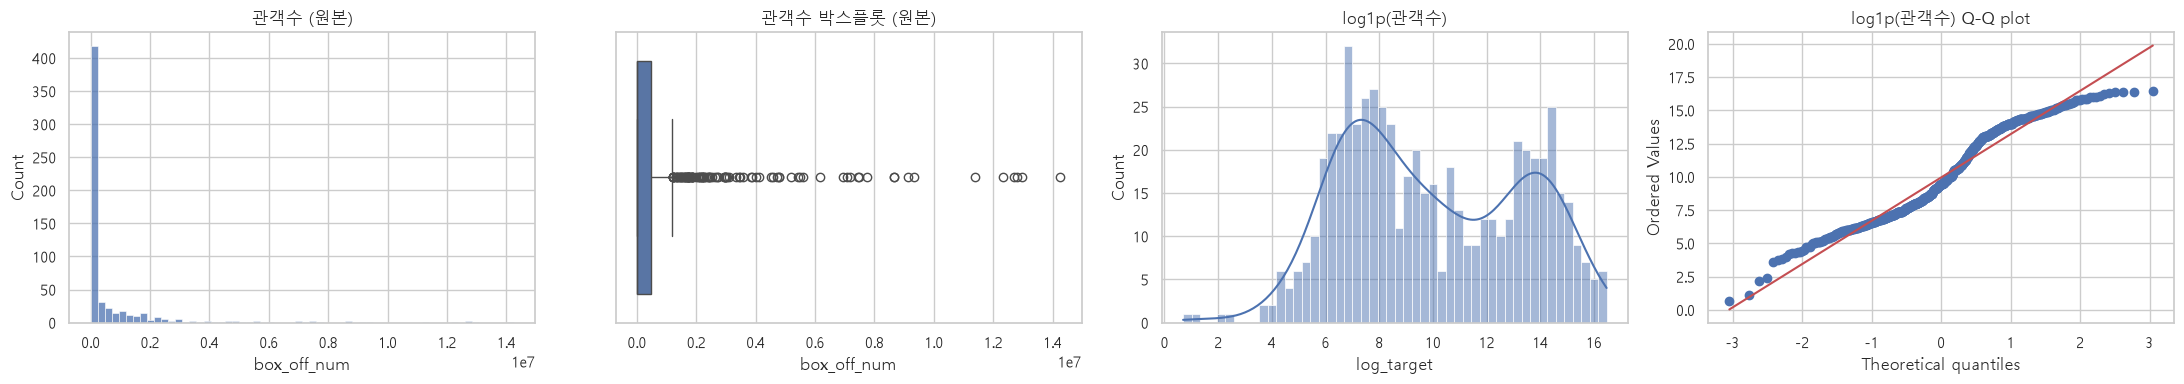

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(22, 4))
sns.histplot(y, bins=60, ax=ax[0]).set_title('관객수 (원본)')
sns.boxplot(x=y, ax=ax[1]).set_title('관객수 박스플롯 (원본)')
sns.histplot(train.log_target, bins=50, kde=True, ax=ax[2]).set_title('log1p(관객수)')
stats.probplot(train.log_target, plot=ax[3])
ax[3].set_title('log1p(관객수) Q-Q plot')
plt.tight_layout(); plt.show()

### 2-1. 대박 영화가 RMSE에 미치는 영향
RMSE는 오차를 **제곱**하기 때문에, 평균에서 멀리 떨어진 소수의 영화가 점수 대부분을 차지함.

In [8]:
s = y.sort_values(ascending=False).reset_index(drop=True)
sq_dev = (s - s.mean()) ** 2  # '평균만 예측했을 때'의 제곱오차

rows = []
for n in [1, 5, 10, 20, 30, 60]:
    rows.append({
        '상위 N편': n,
        '전체 관객수 중 비중(%)': s[:n].sum() / s.sum() * 100,
        '제곱오차(RMSE) 중 비중(%)': sq_dev[:n].sum() / sq_dev.sum() * 100,
    })
display(pd.DataFrame(rows).style.format({'전체 관객수 중 비중(%)': '{:.1f}', '제곱오차(RMSE) 중 비중(%)': '{:.1f}'}))
print(f'평균만 예측했을 때 RMSE (가장 단순한 기준점): {y.std(ddof=0):,.0f}')

,상위 N편,전체 관객수 중 비중(%),제곱오차(RMSE) 중 비중(%)
0,1,3.4,9.2
1,5,15.3,38.0
2,10,26.4,57.2
3,20,42.1,75.3
4,30,52.6,82.4
5,60,71.2,88.3


평균만 예측했을 때 RMSE (가장 단순한 기준점): 1,826,482


In [9]:
cols_show = ['title', TARGET, 'distributor', 'genre', 'screening_rat', 'release_time',
             'time', 'num_staff', 'num_actor', 'dir_prev_num', 'dir_prev_bfnum', 'director']
print('관객수 상위 20편')
display(train.sort_values(TARGET, ascending=False)[cols_show].head(20))
print('관객수 하위 10편')
display(train.sort_values(TARGET)[cols_show].head(10))

관객수 상위 20편


,title,box_off_num,distributor,genre,screening_rat,release_time,time,num_staff,num_actor,dir_prev_num,dir_prev_bfnum,director
372,국제시장,14262766,CJ 엔터테인먼트,드라마,12세 관람가,2014-12-17,126,869,4,0,NaN,윤제균
362,도둑들,12983841,(주)쇼박스,느와르,15세 관람가,2012-07-25,135,462,10,3,2.564692e+06,최동훈
530,7번방의 선물,12811435,(주)NEW,코미디,15세 관람가,2013-01-23,127,300,8,2,8.190495e+05,이환경
498,암살,12706663,(주)쇼박스,액션,15세 관람가,2015-07-22,139,628,3,4,5.169479e+06,최동훈
460,"광해, 왕이 된 남자",12323595,CJ 엔터테인먼트,드라마,15세 관람가,2012-09-13,131,402,3,2,1.552541e+06,추창민
122,변호인,11374879,(주)NEW,드라마,15세 관람가,2013-12-18,127,311,5,0,NaN,양우석
496,설국열차,9350351,CJ 엔터테인먼트,SF,15세 관람가,2013-08-01,125,67,10,0,NaN,봉준호
101,관상,9135806,(주)쇼박스,드라마,15세 관람가,2013-09-11,139,298,6,2,1.242778e+06,한재림
505,해적: 바다로 간 산적,8666208,롯데엔터테인먼트,SF,12세 관람가,2014-08-06,130,868,2,3,1.843895e+06,이석훈
476,수상한 그녀,8659725,CJ 엔터테인먼트,코미디,15세 관람가,2014-01-22,124,437,5,2,2.781990e+06,황동혁


관객수 하위 10편


,title,box_off_num,distributor,genre,screening_rat,release_time,time,num_staff,num_actor,dir_prev_num,dir_prev_bfnum,director
432,젊은 엄마 2,1,골든타이드픽처스,멜로/로맨스,청소년 관람불가,2014-05-29,89,0,1,0,NaN,노성수
324,청아,2,인피니티엔터테인먼트,드라마,청소년 관람불가,2014-09-25,92,3,4,0,NaN,김정호
338,타부 : 금지된 사랑,8,고구마공작소,멜로/로맨스,청소년 관람불가,2015-09-03,78,27,3,1,1.761531e+07,고구마
410,전망 좋은 방-밀애,10,(주) 케이알씨지,멜로/로맨스,청소년 관람불가,2012-11-08,71,0,3,0,NaN,이세일
481,려수,36,(주) 영화사조제,드라마,15세 관람가,2011-11-10,98,1,2,0,NaN,진광교
177,90분,42,사람과 사람들,공포,청소년 관람불가,2012-08-23,94,55,2,0,NaN,박선욱
448,나의 불행에는 이유가 있다,46,위드시네마,드라마,15세 관람가,2010-11-25,86,0,4,0,NaN,한상민
193,러브멘토,54,나우콘텐츠,멜로/로맨스,청소년 관람불가,2014-04-17,74,0,2,1,1.556000e+03,신혜성
168,망대,65,골든타이드픽처스,다큐멘터리,전체 관람가,2015-03-12,66,13,0,0,NaN,문승욱
428,한민족 그리고 조선족,71,한국YWCA연합회,다큐멘터리,전체 관람가,2014-12-10,61,2,6,3,3.453333e+02,전화성


## 3. 결측치: `dir_prev_bfnum` (감독의 이전 작품 평균 관객수)
가설: 결측 = 감독의 **이전 작품이 없음** (데뷔작) → 결측 자체가 정보일 수 있다.

In [10]:
for name, df in [('train', train), ('test', test)]:
    miss = df['dir_prev_bfnum'].isna()
    print(f'[{name}] 결측 {miss.sum()}개 ({miss.mean()*100:.1f}%) · 0인 값 {(df["dir_prev_bfnum"] == 0).sum()}개')
    display(pd.crosstab(miss.map({True: 'bfnum 결측', False: 'bfnum 있음'}),
                        (df['dir_prev_num'] == 0).map({True: '이전 작품 수 = 0', False: '이전 작품 수 ≥ 1'})))

[train] 결측 330개 (55.0%) · 0인 값 0개


dir_prev_num,이전 작품 수 = 0,이전 작품 수 ≥ 1
dir_prev_bfnum,,
bfnum 결측,330,0
bfnum 있음,0,270


[test] 결측 136개 (56.0%) · 0인 값 0개


dir_prev_num,이전 작품 수 = 0,이전 작품 수 ≥ 1
dir_prev_bfnum,,
bfnum 결측,136,0
bfnum 있음,0,107


,count,mean,std,min,25%,50%,75%,max
dir_prev_bfnum,,,,,,,,
값 있음,270,"1,146,932","2,175,028",8,"5,132","222,258","1,403,822","12,983,841"
결측 (이전 기록 없음),330,"349,204","1,388,784",1,834,"3,402","39,766","14,262,766"


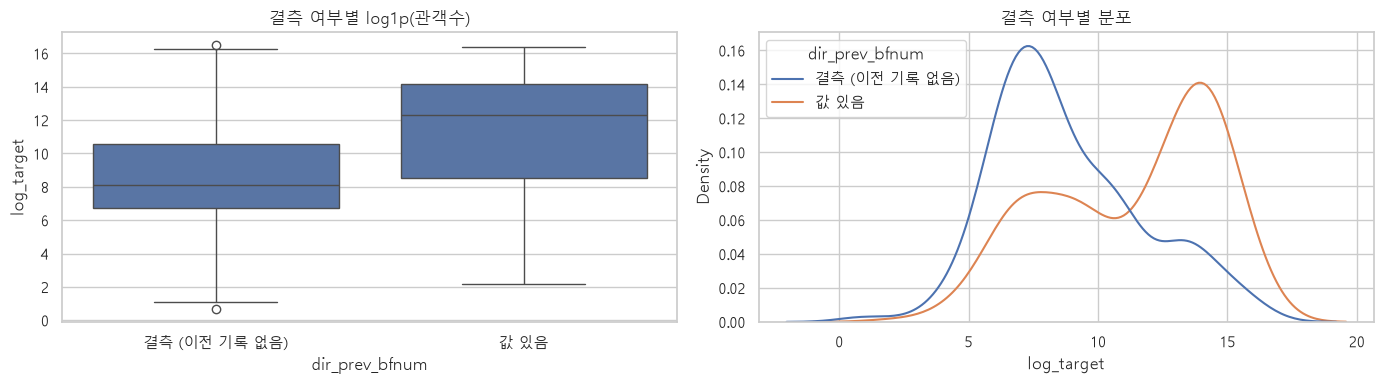

Mann-Whitney U 검정 p-value: 2.14e-19  (작을수록 두 그룹 관객수 차이가 유의함)


In [11]:
miss_flag = train['dir_prev_bfnum'].isna().map({True: '결측 (이전 기록 없음)', False: '값 있음'})
display(train.groupby(miss_flag)[TARGET].describe().style.format('{:,.0f}'))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=miss_flag, y=train.log_target, ax=ax[0]).set_title('결측 여부별 log1p(관객수)')
sns.kdeplot(x=train.log_target, hue=miss_flag, common_norm=False, ax=ax[1]).set_title('결측 여부별 분포')
plt.tight_layout(); plt.show()

stat, p = stats.mannwhitneyu(train.loc[miss_flag == '값 있음', TARGET],
                             train.loc[miss_flag != '값 있음', TARGET])
print(f'Mann-Whitney U 검정 p-value: {p:.2e}  (작을수록 두 그룹 관객수 차이가 유의함)')

## 4. 수치형 변수 하나씩
각 변수마다: 요약 통계 · 이상치 · train/test 분포 · 타깃과의 관계 (원본 / 로그) · 상관계수

In [12]:
def num_report(col):
    s_tr, s_te = train[col], test[col]
    q1, q3 = s_tr.quantile([.25, .75])
    iqr = q3 - q1
    n_out = ((s_tr < q1 - 1.5 * iqr) | (s_tr > q3 + 1.5 * iqr)).sum()

    print(f'■ {col}')
    summary = pd.DataFrame({'train': s_tr.describe(), 'test': s_te.describe()}).T
    summary['결측'] = [s_tr.isna().sum(), s_te.isna().sum()]
    summary['0 개수'] = [(s_tr == 0).sum(), (s_te == 0).sum()]
    summary['왜도'] = [s_tr.skew(), s_te.skew()]
    display(summary.style.format('{:,.2f}'))

    valid = train[[col, TARGET, 'log_target']].dropna()
    pear = valid[col].corr(valid[TARGET])
    pear_log = np.log1p(valid[col]).corr(valid['log_target'])
    spear = valid[col].corr(valid[TARGET], method='spearman')
    print(f'IQR 이상치 {n_out}개 · Pearson(원본) {pear:.3f} · Pearson(log-log) {pear_log:.3f} · Spearman {spear:.3f}')

    fig, ax = plt.subplots(1, 4, figsize=(24, 4))
    bins = np.histogram_bin_edges(pd.concat([s_tr, s_te]).dropna(), bins=40)
    sns.histplot(s_tr, bins=bins, stat='density', color='C0', alpha=.5, label='train', ax=ax[0])
    sns.histplot(s_te, bins=bins, stat='density', color='C1', alpha=.5, label='test', ax=ax[0])
    ax[0].legend(); ax[0].set_title(f'{col} 분포 (train vs test)')
    sns.boxplot(x=s_tr, ax=ax[1]).set_title(f'{col} 박스플롯')
    sns.scatterplot(x=valid[col], y=valid[TARGET], alpha=.5, ax=ax[2]).set_title(f'{col} vs 관객수 (원본)')
    lx = np.log1p(valid[col])
    sns.scatterplot(x=lx, y=valid['log_target'], alpha=.4, ax=ax[3])
    # 추세선: x를 구간으로 나눠 구간별 중앙값을 이은 선
    if lx.nunique() > 10:
        bins_q = pd.qcut(lx, q=10, duplicates='drop')
        trend = valid.groupby(bins_q, observed=True)['log_target'].median()
        centers = lx.groupby(bins_q, observed=True).median()
        ax[3].plot(centers.values, trend.values, color='red', marker='o', label='구간별 중앙값')
        ax[3].legend()
    ax[3].set_xlabel(f'log1p({col})'); ax[3].set_title(f'log1p({col}) vs log1p(관객수)')
    plt.tight_layout(); plt.show()

### 4-1. `time` · 상영 시간 (분)

■ time


,count,mean,std,min,25%,50%,75%,max,결측,0 개수,왜도
train,600.00,100.86,18.10,45.00,89.00,100.00,114.00,180.00,0.00,0.00,0.35
test,243.00,109.80,124.02,40.00,91.00,104.00,114.50,"2,015.00",0.00,0.00,15.10


IQR 이상치 6개 · Pearson(원본) 0.441 · Pearson(log-log) 0.593 · Spearman 0.609


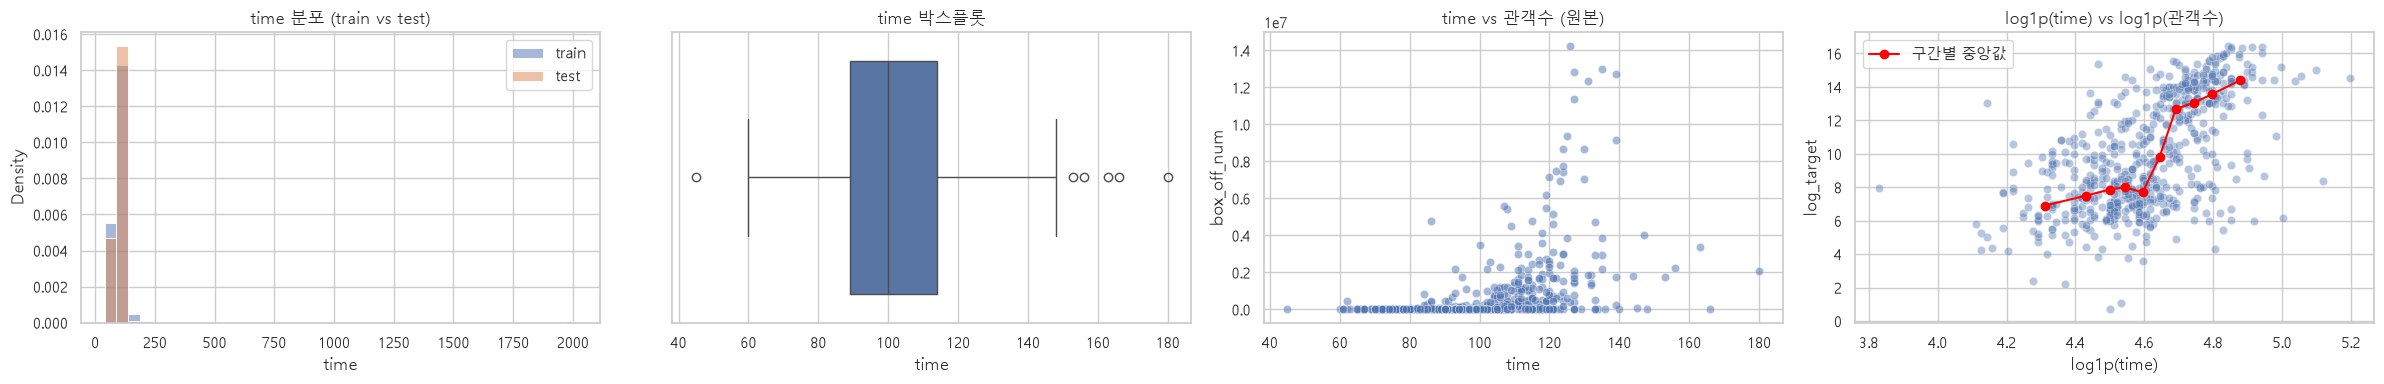

In [13]:
num_report('time')

### 4-2. `dir_prev_bfnum` · 감독의 이전 작품 평균 관객수 (결측 제외)

■ dir_prev_bfnum


,count,mean,std,min,25%,50%,75%,max,결측,0 개수,왜도
train,270.00,"1,050,442.89","1,791,408.30",1.00,"20,380.00","478,423.62","1,286,568.62","17,615,314.00",330.00,0.00,4.42
test,107.00,"891,669.52","1,217,341.45",34.00,"62,502.00","493,120.00","1,080,849.58","6,173,099.50",136.00,0.00,2.25


IQR 이상치 18개 · Pearson(원본) 0.283 · Pearson(log-log) 0.409 · Spearman 0.486


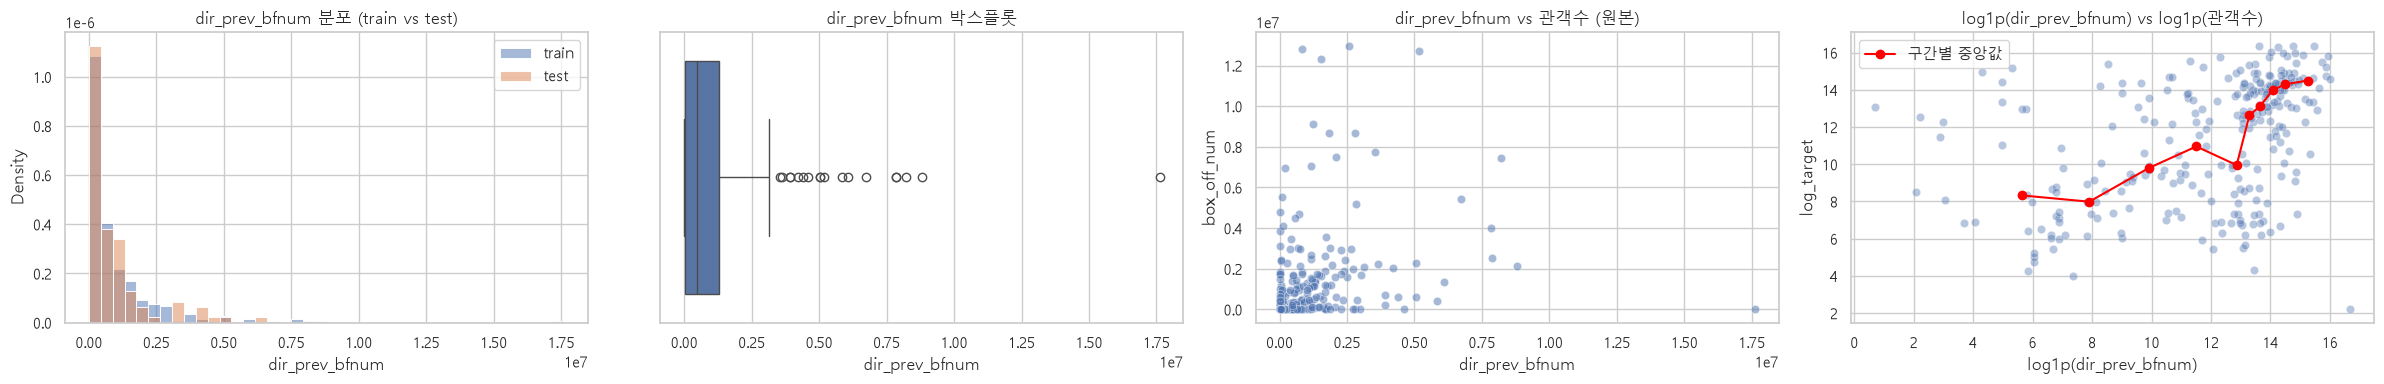

In [14]:
num_report('dir_prev_bfnum')

### 4-3. `dir_prev_num` · 감독의 이전 작품 수

■ dir_prev_num


,count,mean,std,min,25%,50%,75%,max,결측,0 개수,왜도
train,600.00,0.88,1.18,0.00,0.00,0.00,2.00,5.00,0.00,330.00,1.25
test,243.00,0.85,1.20,0.00,0.00,0.00,1.00,6.00,0.00,136.00,1.49


IQR 이상치 0개 · Pearson(원본) 0.260 · Pearson(log-log) 0.411 · Spearman 0.395


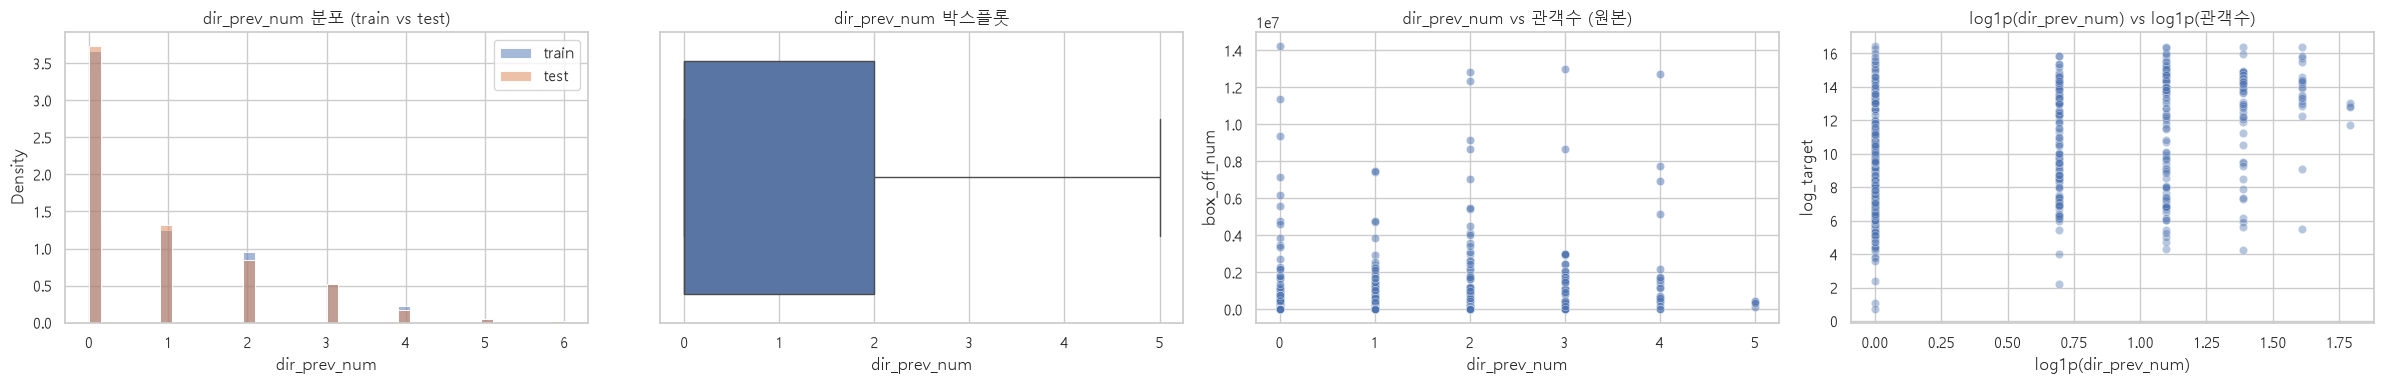

In [15]:
num_report('dir_prev_num')

### 4-4. `num_staff` · 스태프 수 → 제작 규모의 대리 변수일 가능성

■ num_staff


,count,mean,std,min,25%,50%,75%,max,결측,0 개수,왜도
train,600.00,151.12,165.65,0.00,17.00,82.50,264.00,869.00,0.00,32.00,1.23
test,243.00,159.32,162.98,0.00,18.00,105.00,282.00,776.00,0.00,15.00,0.99


IQR 이상치 7개 · Pearson(원본) 0.544 · Pearson(log-log) 0.637 · Spearman 0.695


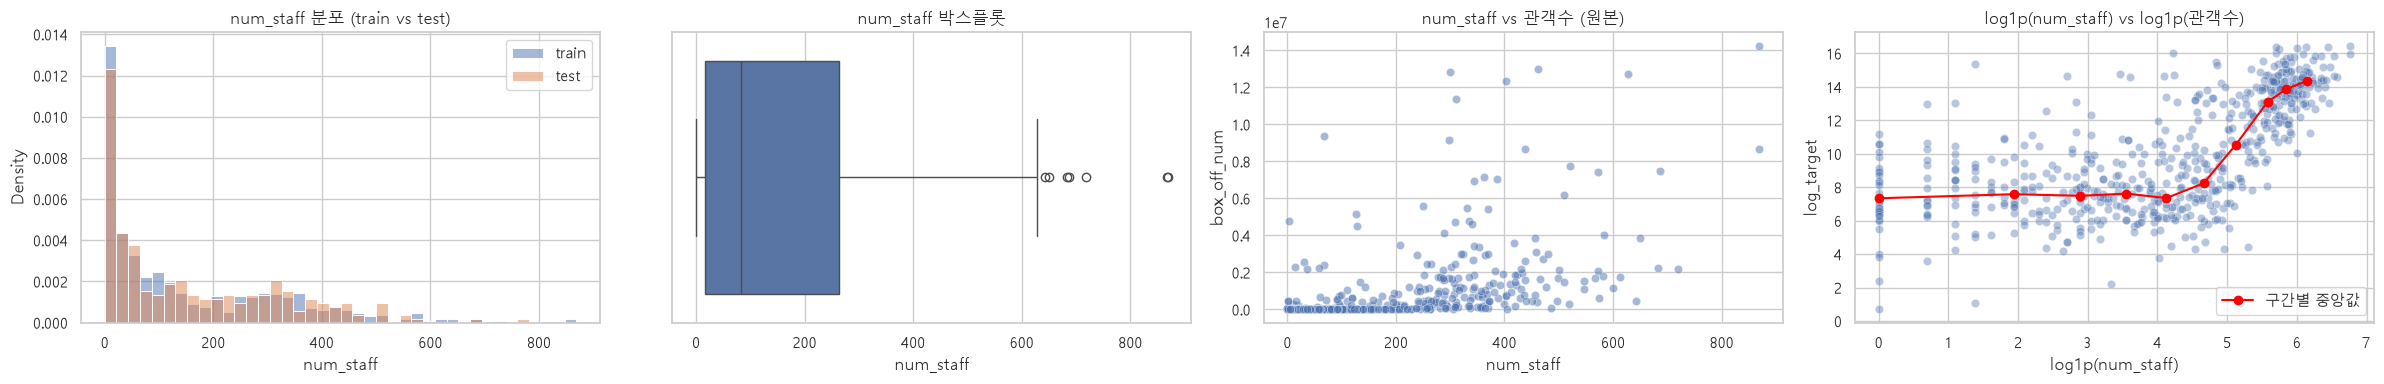

In [16]:
num_report('num_staff')

### 4-5. `num_actor` · 주연 배우 수

■ num_actor


,count,mean,std,min,25%,50%,75%,max,결측,0 개수,왜도
train,600.00,3.71,2.45,0.00,2.00,3.00,4.00,25.00,0.00,9.00,2.95
test,243.00,3.48,2.11,0.00,2.00,3.00,4.00,16.00,0.00,4.00,2.00


IQR 이상치 38개 · Pearson(원본) 0.111 · Pearson(log-log) 0.146 · Spearman 0.127


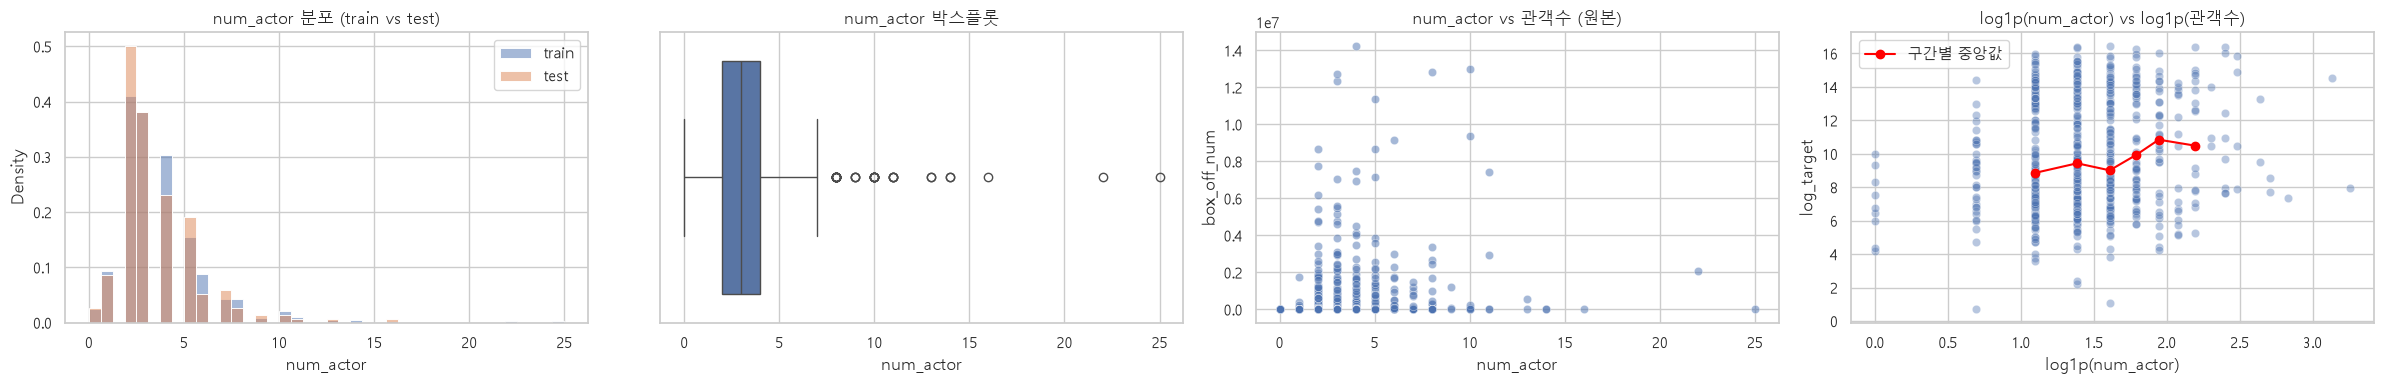

In [17]:
num_report('num_actor')

In [18]:
# 값별로 보는 게 나은 이산형 변수: 값마다 영화 수와 관객수
for col in ['dir_prev_num', 'num_actor']:
    t = train.groupby(col)[TARGET].agg(['count', 'mean', 'median'])
    print(f'■ {col} 값별 관객수')
    display(t.style.format({'mean': '{:,.0f}', 'median': '{:,.0f}'}))

■ dir_prev_num 값별 관객수


,count,mean,median
dir_prev_num,,,
0,330,"349,204","3,402"
1,113,"656,102","38,809"
2,86,"1,414,767","180,706"
3,47,"1,388,813","828,029"
4,20,"2,362,598","1,174,766"
5,4,"334,003","371,255"


■ num_actor 값별 관객수


,count,mean,median
num_actor,,,
0,9,"4,498",862
1,35,"86,102","8,083"
2,154,"598,755","9,264"
3,143,"761,741","12,486"
4,114,"650,545","8,208"
5,58,"979,365","20,690"
6,33,"671,746","51,207"
7,16,"342,733","19,178"
8,16,"1,564,733","295,863"


## 5. 범주형 변수 하나씩
각 변수마다: 고유값 수 · 빈도 · 범주별 관객수 (평균 / 중앙값) · test에만 있는 범주 · 박스플롯 · Kruskal-Wallis 검정

In [19]:
def cat_report(col, top=None):
    vc = train[col].value_counts()
    print(f'■ {col} · train 고유값 {vc.size}개 · test 고유값 {test[col].nunique()}개')

    unseen = set(test[col]) - set(train[col])
    print(f'test에만 있는 범주: {len(unseen)}개 (test {test[col].isin(unseen).sum()}행)')

    g = train.groupby(col)[TARGET].agg(['count', 'mean', 'median', 'max'])
    g['비중(%)'] = g['count'] / len(train) * 100
    g['log 평균'] = train.groupby(col)['log_target'].mean()
    g['test 개수'] = test[col].value_counts().reindex(g.index).fillna(0).astype(int)
    g = g.sort_values('count', ascending=False)
    display(g.head(top).style.format({'mean': '{:,.0f}', 'median': '{:,.0f}', 'max': '{:,.0f}',
                                       '비중(%)': '{:.1f}', 'log 평균': '{:.2f}'}))

    groups = [grp['log_target'].values for _, grp in train.groupby(col) if len(grp) >= 3]
    if len(groups) >= 2:
        print(f'Kruskal-Wallis p-value (log 관객수): {stats.kruskal(*groups).pvalue:.2e}')

    order_cnt = vc.index[:top] if top else vc.index
    order_med = (train[train[col].isin(order_cnt)].groupby(col)['log_target']
                 .median().sort_values(ascending=False).index)
    h = max(4, 0.35 * len(order_cnt))
    fig, ax = plt.subplots(1, 2, figsize=(20, h))
    sns.countplot(y=train[col], order=order_cnt, ax=ax[0]).set_title(f'{col} 빈도')
    sns.boxplot(y=train[col], x=train['log_target'], order=order_med, ax=ax[1])
    ax[1].set_title(f'{col}별 log1p(관객수) (중앙값 순)')
    plt.tight_layout(); plt.show()

### 5-1. `genre` · 장르

■ genre · train 고유값 12개 · test 고유값 12개
test에만 있는 범주: 0개 (test 0행)


,count,mean,median,max,비중(%),log 평균,test 개수
genre,,,,,,,
드라마,221,"625,690","7,173","14,262,766",36.8,9.69,78
다큐멘터리,93,"67,172","3,044","4,802,169",15.5,8.23,33
멜로/로맨스,78,"425,968","3,653","4,598,985",13.0,9.18,39
코미디,53,"1,193,914","210,775","12,811,435",8.8,11.45,23
공포,42,"590,833","179,810","5,604,106",7.0,11.11,19
액션,28,"2,203,974","1,147,846","12,706,663",4.7,12.90,21
느와르,27,"2,263,695","1,646,142","12,983,841",4.5,12.81,12
애니메이션,21,"181,927","23,802","2,202,788",3.5,10.06,8
미스터리,17,"527,548","3,199","5,443,049",2.8,9.25,7


Kruskal-Wallis p-value (log 관객수): 3.14e-13


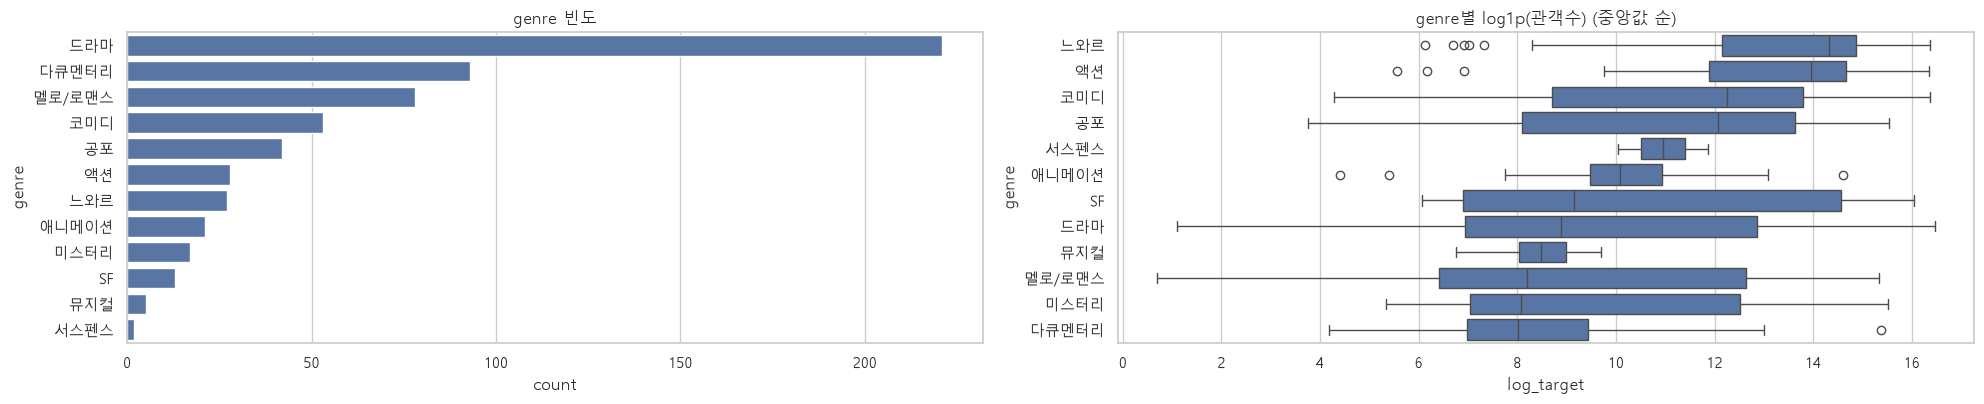

In [20]:
cat_report('genre')

### 5-2. `screening_rat` · 관람 등급

■ screening_rat · train 고유값 4개 · test 고유값 4개
test에만 있는 범주: 0개 (test 0행)


,count,mean,median,max,비중(%),log 평균,test 개수
screening_rat,,,,,,,
청소년 관람불가,204,"364,181","3,008","7,072,501",34.0,8.98,93
15세 관람가,202,"1,247,519","242,381","12,983,841",33.7,11.22,73
12세 관람가,102,"844,981","19,323","14,262,766",17.0,10.29,40
전체 관람가,92,"135,100","8,325","4,802,169",15.3,8.94,37


Kruskal-Wallis p-value (log 관객수): 3.36e-11


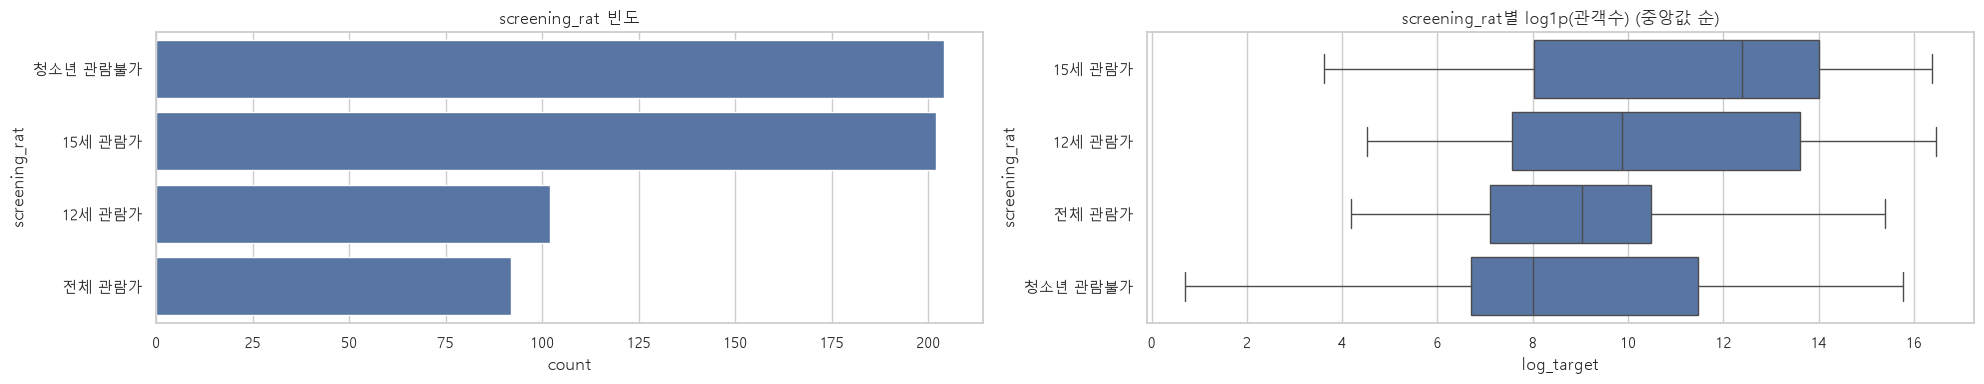

In [21]:
cat_report('screening_rat')

#### 5-2-1. 관람 등급별 흥행 여부 자세히 보기
흥행 기준: **100만 이상 = 흥행**, **500만 이상 = 대박**, **1만 미만 = 소규모**
등급마다 흥행 확률이 얼마나 다른지, 대박 영화(=RMSE를 좌우하는 영화)가 어떤 등급에 몰려 있는지 확인.

In [22]:
RAT_ORDER = ['전체 관람가', '12세 관람가', '15세 관람가', '청소년 관람불가']

hit = pd.cut(train[TARGET], bins=[-1, 10_000, 100_000, 1_000_000, 5_000_000, np.inf],
             labels=['1만 미만', '1만~10만', '10만~100만', '100만~500만', '500만 이상'])
train['hit_level'] = hit

r = train.groupby('screening_rat').agg(
    영화수=(TARGET, 'size'),
    평균=(TARGET, 'mean'),
    중앙값=(TARGET, 'median'),
    흥행률_100만=(TARGET, lambda s: (s >= 1_000_000).mean() * 100),
    대박률_500만=(TARGET, lambda s: (s >= 5_000_000).mean() * 100),
    소규모율_1만미만=(TARGET, lambda s: (s < 10_000).mean() * 100),
).reindex(RAT_ORDER)
r['전체 관객 중 비중(%)'] = train.groupby('screening_rat')[TARGET].sum().reindex(RAT_ORDER) / train[TARGET].sum() * 100
sq = (train[TARGET] - train[TARGET].mean()) ** 2
r['RMSE 제곱오차 중 비중(%)'] = sq.groupby(train['screening_rat']).sum().reindex(RAT_ORDER) / sq.sum() * 100
r['test 영화수'] = test['screening_rat'].value_counts().reindex(RAT_ORDER)
display(r.style.format({'평균': '{:,.0f}', '중앙값': '{:,.0f}', '흥행률_100만': '{:.1f}%', '대박률_500만': '{:.1f}%',
                        '소규모율_1만미만': '{:.1f}%', '전체 관객 중 비중(%)': '{:.1f}', 'RMSE 제곱오차 중 비중(%)': '{:.1f}'}))

,영화수,평균,중앙값,흥행률_100만,대박률_500만,소규모율_1만미만,전체 관객 중 비중(%),RMSE 제곱오차 중 비중(%),test 영화수
screening_rat,,,,,,,,,
전체 관람가,92,"135,100","8,325",2.2%,0.0%,53.3%,2.9,2.9,37
12세 관람가,102,"844,981","19,323",20.6%,3.9%,45.1%,20.3,20.7,40
15세 관람가,202,"1,247,519","242,381",30.2%,7.4%,33.7%,59.3,65.1,73
청소년 관람불가,204,"364,181","3,008",12.3%,1.0%,61.3%,17.5,11.3,93


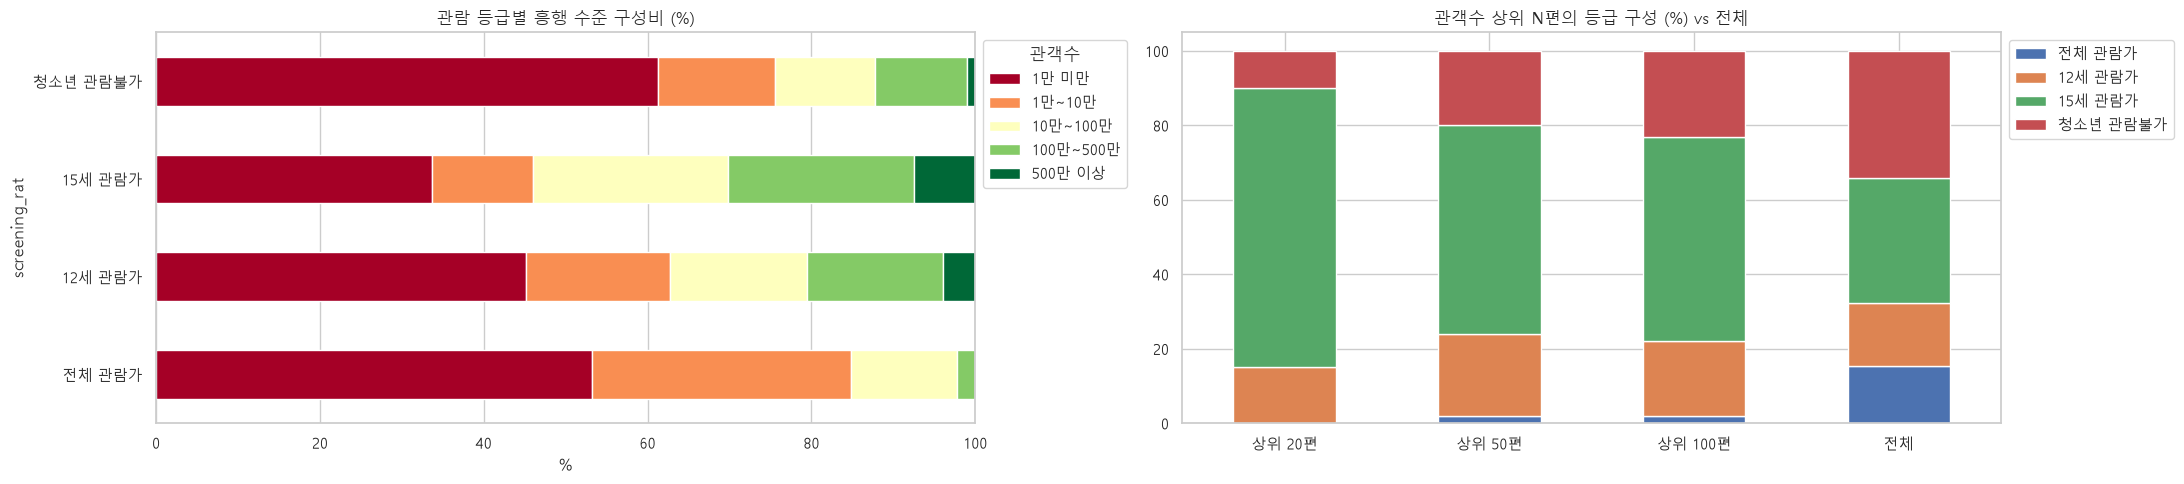

In [23]:
# 등급별 흥행 수준 구성비 (100% 누적 막대)
ct = pd.crosstab(train['screening_rat'], train['hit_level'], normalize='index').reindex(RAT_ORDER) * 100
fig, ax = plt.subplots(1, 2, figsize=(22, 5))
ct.plot.barh(stacked=True, colormap='RdYlGn', ax=ax[0])
ax[0].set_title('관람 등급별 흥행 수준 구성비 (%)'); ax[0].set_xlabel('%')
ax[0].legend(title='관객수', bbox_to_anchor=(1, 1))

# 관객수 상위 N편 안에서 등급 구성
top_mix = {}
for n in [20, 50, 100]:
    top_mix[f'상위 {n}편'] = train.nlargest(n, TARGET)['screening_rat'].value_counts(normalize=True) * 100
top_mix['전체'] = train['screening_rat'].value_counts(normalize=True) * 100
pd.DataFrame(top_mix).reindex(RAT_ORDER).T.plot.bar(stacked=True, ax=ax[1], rot=0)
ax[1].set_title('관객수 상위 N편의 등급 구성 (%) vs 전체'); ax[1].legend(bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

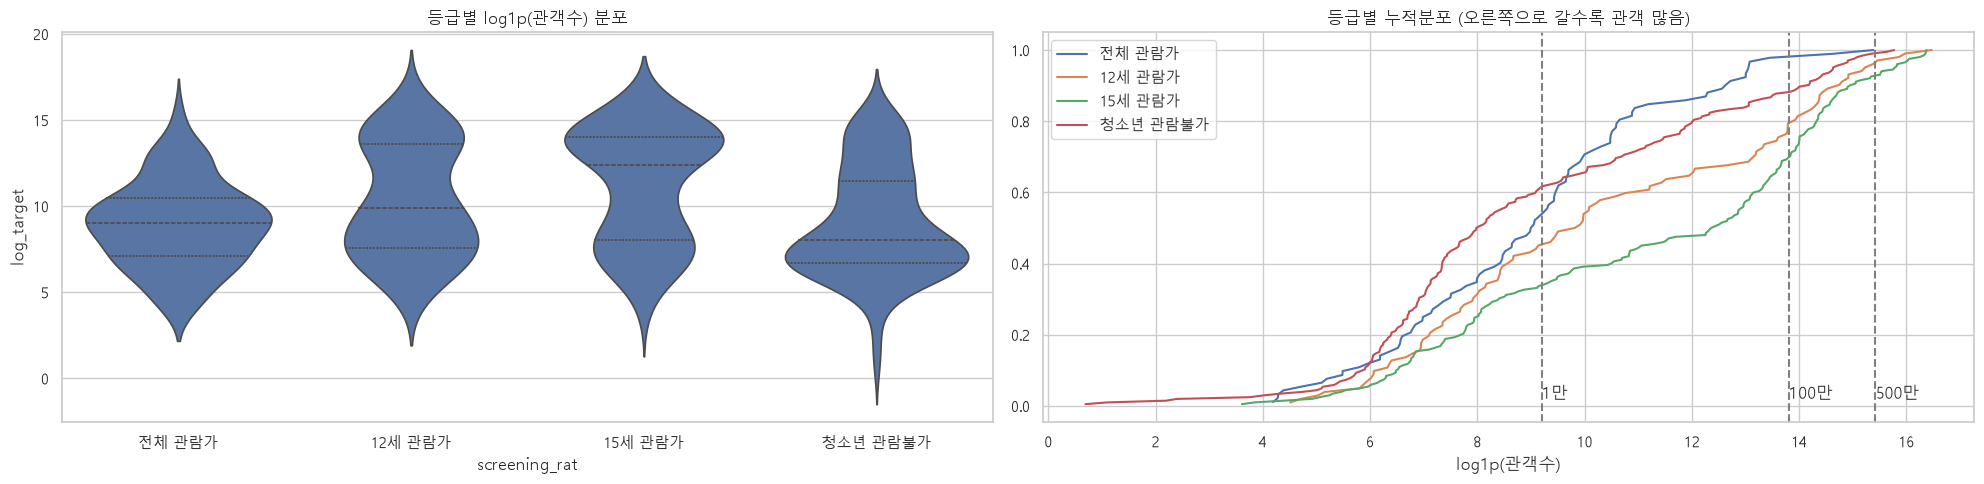

In [24]:
# 등급별 관객수 분포 비교 (원본 로그 스케일 / 누적분포)
fig, ax = plt.subplots(1, 2, figsize=(20, 5))
sns.violinplot(data=train, x='screening_rat', y='log_target', order=RAT_ORDER, inner='quartile', ax=ax[0])
ax[0].set_title('등급별 log1p(관객수) 분포')
for rat in RAT_ORDER:
    v = np.sort(train.loc[train['screening_rat'] == rat, 'log_target'])
    ax[1].plot(v, np.arange(1, len(v) + 1) / len(v), label=rat)
for x, lab in [(np.log1p(1e4), '1만'), (np.log1p(1e6), '100만'), (np.log1p(5e6), '500만')]:
    ax[1].axvline(x, color='gray', ls='--'); ax[1].text(x, 0.02, lab)
ax[1].set_title('등급별 누적분포 (오른쪽으로 갈수록 관객 많음)'); ax[1].set_xlabel('log1p(관객수)'); ax[1].legend()
plt.tight_layout(); plt.show()

,num_staff,time,num_actor
screening_rat,,,
전체 관람가,9,86,4
12세 관람가,72,99,3
15세 관람가,202,108,3
청소년 관람불가,78,97,3


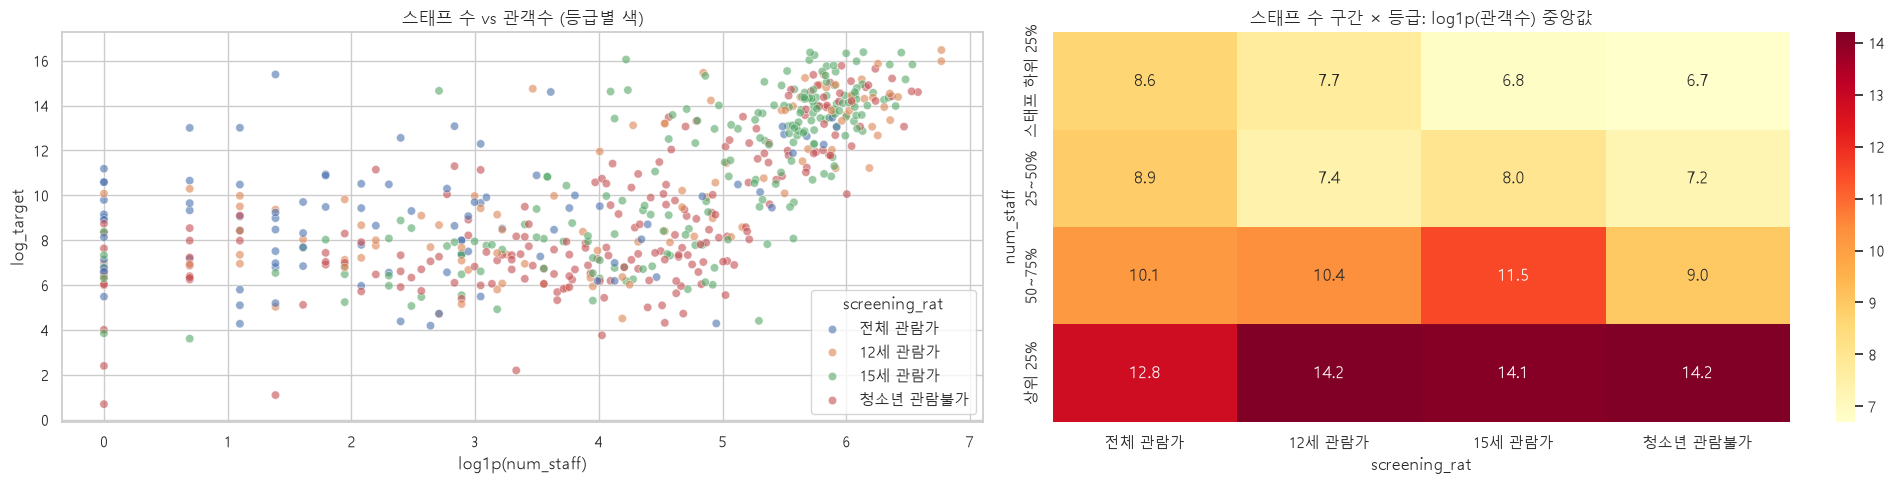

In [25]:
# 등급 효과가 '등급 자체' 때문인지, 등급에 따라 제작 규모가 달라서인지 확인
display(train.groupby('screening_rat')[['num_staff', 'time', 'num_actor']].median().reindex(RAT_ORDER)
        .style.format('{:,.0f}').set_caption('등급별 제작 규모 (중앙값)'))

fig, ax = plt.subplots(1, 2, figsize=(20, 5))
sns.scatterplot(data=train, x=np.log1p(train['num_staff']), y='log_target', hue='screening_rat',
                hue_order=RAT_ORDER, alpha=.6, ax=ax[0])
ax[0].set_xlabel('log1p(num_staff)'); ax[0].set_title('스태프 수 vs 관객수 (등급별 색)')

# 스태프 수 구간을 맞춰 놓고 등급별로 비교 → 같은 규모일 때도 등급 차이가 있는지
staff_bin = pd.qcut(train['num_staff'], q=4, labels=['스태프 하위 25%', '25~50%', '50~75%', '상위 25%'])
pv = train.pivot_table(index=staff_bin, columns='screening_rat', values='log_target', aggfunc='median', observed=True)[RAT_ORDER]
sns.heatmap(pv, annot=True, fmt='.1f', cmap='YlOrRd', ax=ax[1])
ax[1].set_title('스태프 수 구간 × 등급: log1p(관객수) 중앙값')
plt.tight_layout(); plt.show()

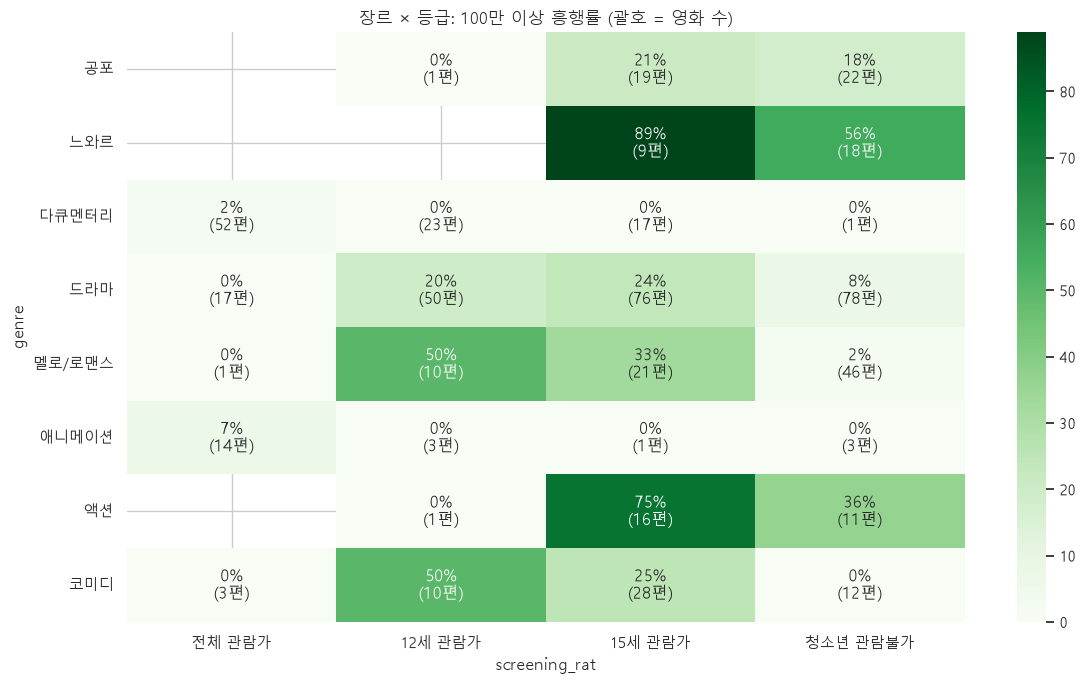

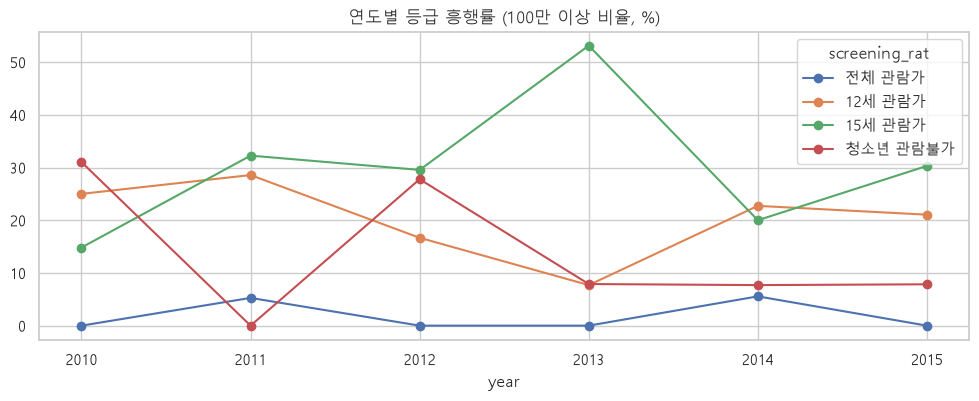

In [26]:
# 등급 × 장르: 흥행률 (100만 이상 비율)과 영화 수
top_genre = train['genre'].value_counts().index[:8]
sub = train[train['genre'].isin(top_genre)]
rate = sub.pivot_table(index='genre', columns='screening_rat', values=TARGET,
                       aggfunc=lambda s: (s >= 1_000_000).mean() * 100)[RAT_ORDER]
cnt = pd.crosstab(sub['genre'], sub['screening_rat'])[RAT_ORDER]
annot = rate.round(0).astype('Int64').astype(str) + '%\n(' + cnt.astype(str) + '편)'
fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(rate, annot=annot.values, fmt='', cmap='Greens', ax=ax)
ax.set_title('장르 × 등급: 100만 이상 흥행률 (괄호 = 영화 수)')
plt.tight_layout(); plt.show()

# 연도별 등급 흥행률 추이
yr = train.assign(year=pd.to_datetime(train['release_time']).dt.year).pivot_table(
    index='year', columns='screening_rat', values=TARGET, aggfunc=lambda s: (s >= 1_000_000).mean() * 100)[RAT_ORDER]
yr.plot(marker='o', figsize=(12, 4), title='연도별 등급 흥행률 (100만 이상 비율, %)')
plt.show()

In [27]:
# 등급 간 관객수 차이 검정 (두 등급씩 비교, Bonferroni 보정)
from itertools import combinations
pairs = list(combinations(RAT_ORDER, 2))
rows = []
for a, b in pairs:
    p = stats.mannwhitneyu(train.loc[train['screening_rat'] == a, TARGET],
                           train.loc[train['screening_rat'] == b, TARGET]).pvalue
    rows.append({'비교': f'{a} vs {b}', 'p-value': p, '보정 p-value': min(p * len(pairs), 1)})
display(pd.DataFrame(rows).style.format({'p-value': '{:.2e}', '보정 p-value': '{:.2e}'}))
print('보정 p-value < 0.05 이면 두 등급의 관객수 차이가 통계적으로 유의함')

,비교,p-value,보정 p-value
0,전체 관람가 vs 12세 관람가,9.48e-03,5.69e-02
1,전체 관람가 vs 15세 관람가,7.35e-08,4.41e-07
2,전체 관람가 vs 청소년 관람불가,5.90e-01,1.00e+00
3,12세 관람가 vs 15세 관람가,3.65e-02,2.19e-01
4,12세 관람가 vs 청소년 관람불가,9.59e-04,5.75e-03
5,15세 관람가 vs 청소년 관람불가,1.76e-10,1.06e-09


보정 p-value < 0.05 이면 두 등급의 관객수 차이가 통계적으로 유의함


### 5-3. `distributor` · 배급사
고유값이 많아서 상위 25개만 표시. 같은 회사가 다른 이름으로 적혀 있는지도 확인.

■ distributor · train 고유값 169개 · test 고유값 93개
test에만 있는 범주: 35개 (test 36행)


,count,mean,median,max,비중(%),log 평균,test 개수
distributor,,,,,,,
CJ 엔터테인먼트,54,"2,162,742","1,136,188","14,262,766",9.0,12.61,31
롯데엔터테인먼트,52,"1,238,149","612,772","8,666,208",8.7,13.08,24
(주)NEW,30,"2,184,405","1,066,769","12,811,435",5.0,13.57,6
(주)마운틴픽쳐스,29,"32,342","1,198","444,327",4.8,7.36,14
(주)쇼박스,26,"3,386,656","2,138,560","12,983,841",4.3,14.50,12
인디스토리,26,"5,211","2,612","36,841",4.3,7.95,11
골든타이드픽처스,15,"4,373",599,"39,577",2.5,6.34,12
(주) 케이알씨지,14,"1,027",630,"2,821",2.3,6.42,5
(주) 영화사조제,10,"6,772","1,380","46,212",1.7,7.02,2


Kruskal-Wallis p-value (log 관객수): 6.93e-41


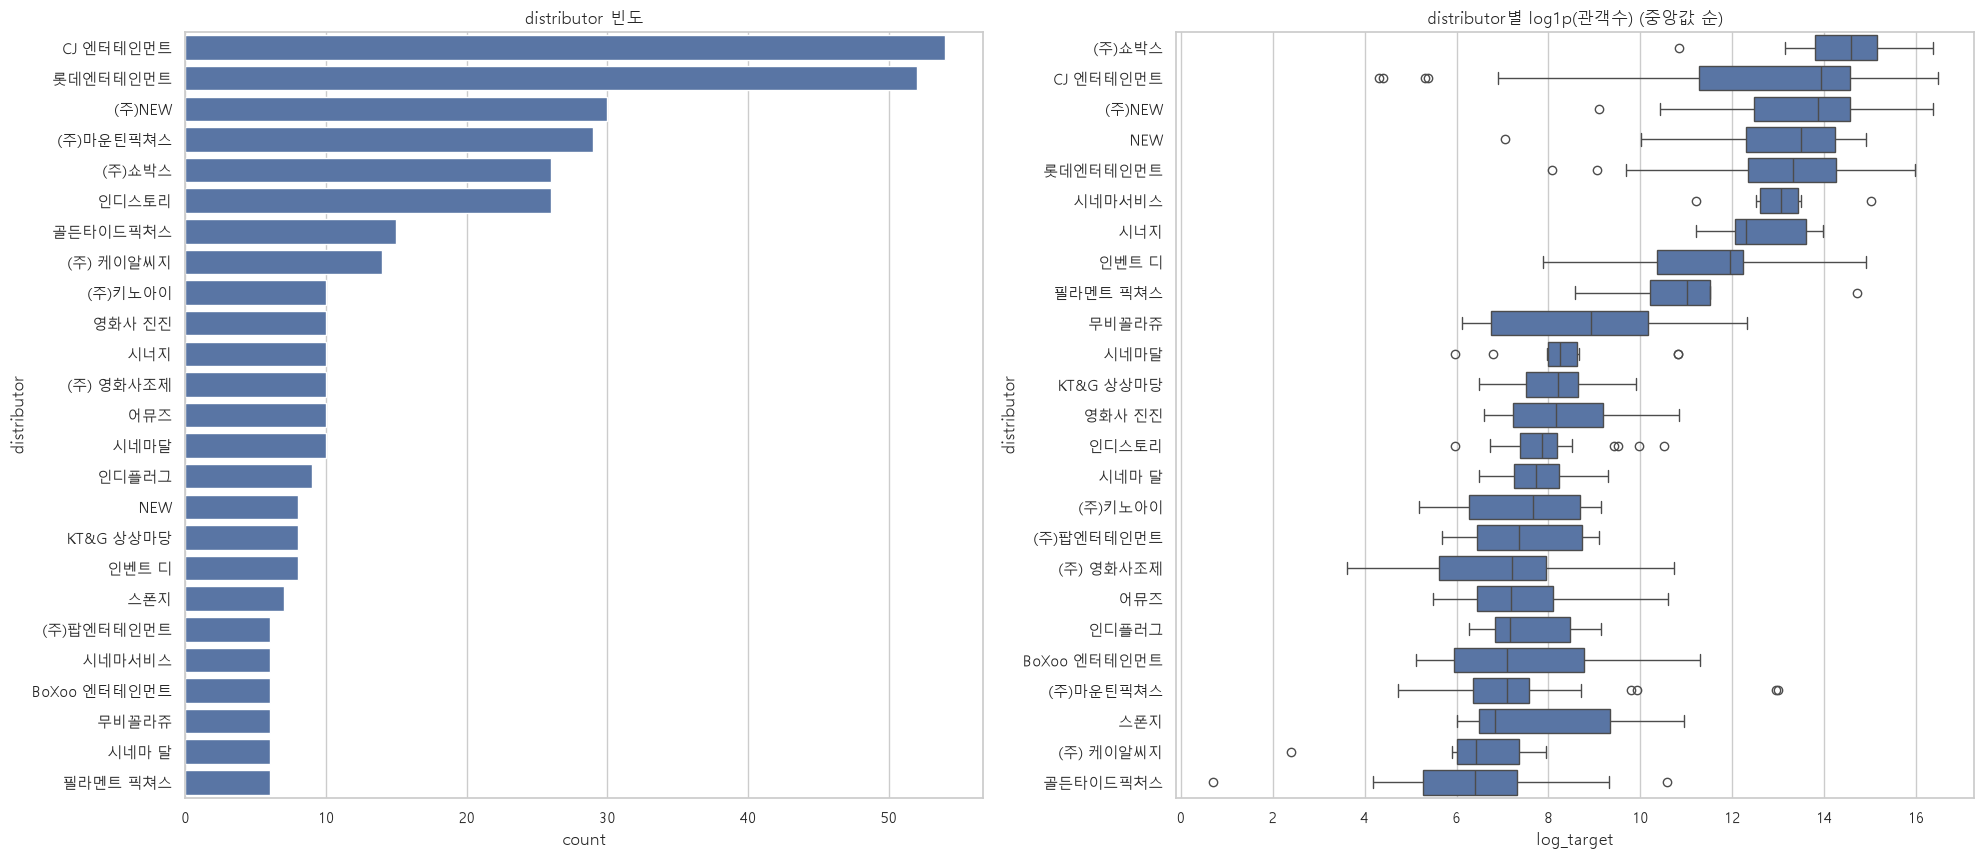

In [28]:
cat_report('distributor', top=25)

In [29]:
# 배급사 이름 표기가 여러 개로 나뉘어 있는지 확인 (예: '(주)쇼박스' / '쇼박스(주)미디어플렉스')
def norm_name(x):
    return re.sub(r'\(주\)|㈜|주식회사|\s', '', x)

all_dist = pd.concat([train['distributor'], test['distributor']]).drop_duplicates()
norm = all_dist.map(norm_name)
for key in ['CJ', '롯데', 'NEW', '쇼박스', '마운틴', '인디스토리', '시네마서비스', '메가박스', '워너', '소니', '이십세기', '디씨지', '리틀빅']:
    hits = sorted(all_dist[norm.str.contains(key, case=False)])
    if len(hits) > 1:
        print(f'{key}: {hits}')

print('\n정규화 전 고유값', all_dist.size, '→ 정규화 후', norm.nunique())

CJ: ['CJ CGV', 'CJ E&M Pictures', 'CJ E&M 영화부문', 'CJ 엔터테인먼트']
롯데: ['롯데쇼핑(주)롯데엔터테인먼트', '롯데엔터테인먼트']
NEW: ['(주)NEW', 'NEW']
쇼박스: ['(주)쇼박스', '쇼박스(주)미디어플렉스']
마운틴: ['(주)마운틴픽쳐스', '(주)씨타마운틴픽쳐스', '더픽쳐스/(주)마운틴픽쳐스', '마운틴 픽처스', '마운틴픽쳐스']
메가박스: ['메가박스(주)플러스엠', '메가박스중앙(주)플러스엠']
리틀빅: ['(주)리틀빅픽처스', '리틀빅픽처스', '리틀빅픽쳐스']

정규화 전 고유값 204 → 정규화 후 191


,count,mean,median
distributor,,,
1편,102,"136,877","2,862"
2~3편,82,"440,099","14,612"
4~10편,170,"229,112","5,485"
11~25편,29,"2,758",599
26편 이상,217,"1,547,606","472,695"


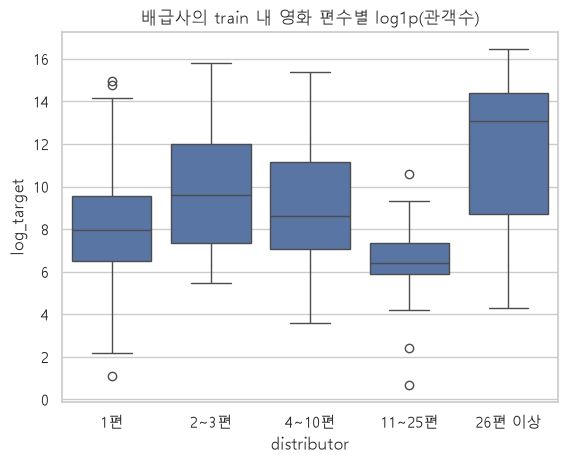

In [30]:
# 배급사 규모(영화 편수) 구간별 관객수: '상위 5개 + 기타' 묶음이 적절한지 확인
dist_cnt = train['distributor'].map(train['distributor'].value_counts())
bucket = pd.cut(dist_cnt, bins=[0, 1, 3, 10, 25, 100], labels=['1편', '2~3편', '4~10편', '11~25편', '26편 이상'])
display(train.groupby(bucket, observed=True)[TARGET].agg(['count', 'mean', 'median']).style.format({'mean': '{:,.0f}', 'median': '{:,.0f}'}))
sns.boxplot(x=bucket, y=train['log_target']).set_title('배급사의 train 내 영화 편수별 log1p(관객수)')
plt.show()

## 6. 날짜: `release_time` (개봉일)

In [31]:
WEEKDAY = ['월', '화', '수', '목', '금', '토', '일']
for df in (train, test):
    d = pd.to_datetime(df['release_time'])
    df['year'] = d.dt.year
    df['month'] = d.dt.month
    df['weekday'] = d.dt.dayofweek.map(dict(enumerate(WEEKDAY)))
    df['quarter'] = d.dt.quarter

print('train 개봉일 범위:', train['release_time'].min(), '~', train['release_time'].max())
print('test  개봉일 범위:', test['release_time'].min(), '~', test['release_time'].max())

train 개봉일 범위: 2010-01-02 ~ 2015-12-31
test  개봉일 범위: 2010-01-07 ~ 2015-12-17


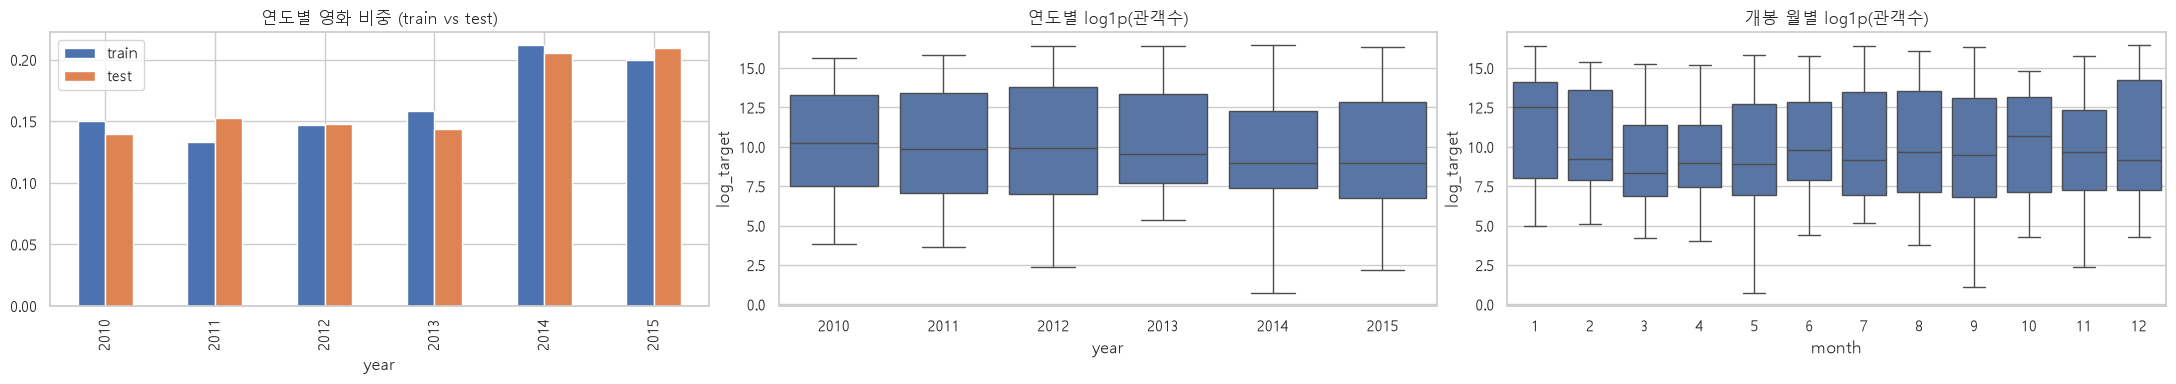

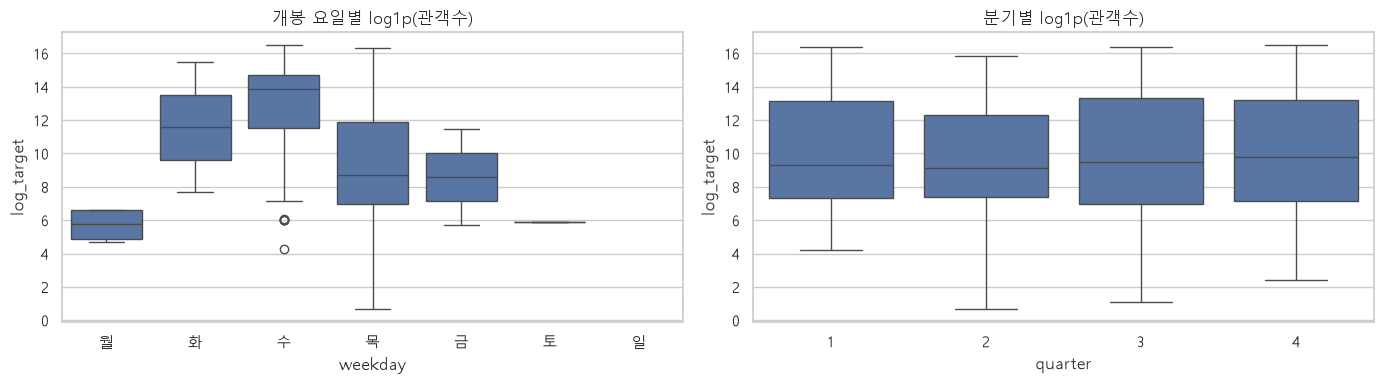

■ year


year,2010,2011,2012,2013,2014,2015
count,90,80,88,95,127,120
mean,"541,658","628,867","945,725","1,007,358","593,884","595,869"
median,"28,376","18,904","20,688","14,188","7,721","7,988"


■ month


month,1,2,3,4,5,6,7,8,9,10,11,12
count,39,31,52,47,57,29,49,55,60,60,72,49
mean,"1,365,931","663,025","273,887","258,167","575,685","512,286","1,113,807","1,029,162","731,529","385,904","495,654","1,288,248"
median,"283,449","10,203","4,110","7,956","7,448","18,343","9,301","16,248","14,931","45,112","15,813","9,323"


■ weekday


weekday,금,목,수,월,토,화
count,2,484,107,4,1,2
mean,"48,651","372,299","2,237,699",434,353,"2,591,569"
median,"48,651","5,922","1,025,243",440,353,"2,591,569"


■ quarter


quarter,1,2,3,4
count,122,133,164,181
mean,"721,862","449,656","945,562","673,842"
median,"11,304","9,438","13,484","17,341"


In [32]:
fig, ax = plt.subplots(1, 3, figsize=(22, 4))
yc = pd.DataFrame({'train': train['year'].value_counts(normalize=True),
                   'test': test['year'].value_counts(normalize=True)}).sort_index()
yc.plot.bar(ax=ax[0], title='연도별 영화 비중 (train vs test)')
sns.boxplot(x=train['year'], y=train['log_target'], ax=ax[1]).set_title('연도별 log1p(관객수)')
sns.boxplot(x=train['month'], y=train['log_target'], ax=ax[2]).set_title('개봉 월별 log1p(관객수)')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=train['weekday'], y=train['log_target'], order=WEEKDAY, ax=ax[0]).set_title('개봉 요일별 log1p(관객수)')
sns.boxplot(x=train['quarter'], y=train['log_target'], ax=ax[1]).set_title('분기별 log1p(관객수)')
plt.tight_layout(); plt.show()

for col in ['year', 'month', 'weekday', 'quarter']:
    t = train.groupby(col)[TARGET].agg(['count', 'mean', 'median'])
    print(f'■ {col}')
    display(t.T.style.format('{:,.0f}'))

## 7. 감독 · 제목

In [33]:
dc = train['director'].value_counts()
print(f'train 감독 {dc.size}명 · 2편 이상 감독 {(dc >= 2).sum()}명')
in_train = test['director'].isin(train['director'])
print(f'test 영화 중 감독이 train에도 있는 영화: {in_train.sum()}편 / {len(test)}편 ({in_train.mean()*100:.1f}%)')

multi = train[train['director'].isin(dc[dc >= 2].index)]
display(multi.sort_values(['director', 'release_time'])[['director', 'title', 'release_time', TARGET, 'dir_prev_num', 'dir_prev_bfnum']].head(30))

train 감독 472명 · 2편 이상 감독 99명
test 영화 중 감독이 train에도 있는 영화: 89편 / 243편 (36.6%)


,director,title,release_time,box_off_num,dir_prev_num,dir_prev_bfnum
209,강우석,이끼,2010-07-14,3350311,0,NaN
422,강우석,전설의 주먹,2013-04-10,1744585,3,8.448210e+05
16,강형철,써니,2011-05-04,7453715,1,8.223342e+06
409,강형철,타짜-신의 손,2014-09-03,4015364,2,7.838528e+06
146,곽경택,통증,2011-09-07,700272,0,NaN
59,곽경택,친구 2,2013-11-14,2971475,2,3.728630e+05
384,구혜선,복숭아나무,2012-10-31,33902,0,NaN
223,구혜선,다우더,2014-11-06,3789,0,NaN
270,권칠인,참을 수 없는,2010-10-21,75740,0,NaN
55,권칠인,원더풀 라디오,2012-01-05,986287,1,7.574000e+04


In [34]:
# 제목 기반 파생변수 후보: 제목 길이, 숫자 포함(속편 가능성), 부제(':' 등) 포함
for df in (train, test):
    df['title_len'] = df['title'].str.len()
    df['title_has_digit'] = df['title'].str.contains(r'\d').astype(int)
    df['title_has_sub'] = df['title'].str.contains(r'[:：\-]').astype(int)

for col in ['title_has_digit', 'title_has_sub']:
    print(f'■ {col}')
    display(train.groupby(col)[TARGET].agg(['count', 'mean', 'median']).style.format({'mean': '{:,.0f}', 'median': '{:,.0f}'}))
print('제목 길이 vs log 관객수 Spearman:', round(train['title_len'].corr(train['log_target'], method='spearman'), 3))
print('숫자 포함 제목 예시:', train.loc[train['title_has_digit'] == 1, 'title'].head(10).tolist())

■ title_has_digit


,count,mean,median
title_has_digit,,,
0,561,"709,293","12,950"
1,39,"692,193","8,083"


■ title_has_sub


,count,mean,median
title_has_sub,,,
0,540,"714,830","13,310"
1,60,"648,344","5,701"


제목 길이 vs log 관객수 Spearman: -0.132
숫자 포함 제목 예시: ['1789, 바스티유의 연인들', '7월 32일', '친구 2', '청포도 사탕: 17년 전의 약속', '원 오브 어 카인드 3D', '덕수리 5형제', '26년', '고녀석 맛나겠다2 : 함께라서 행복해', '정글피쉬2', '7광구']


## 8. 변수 간 관계

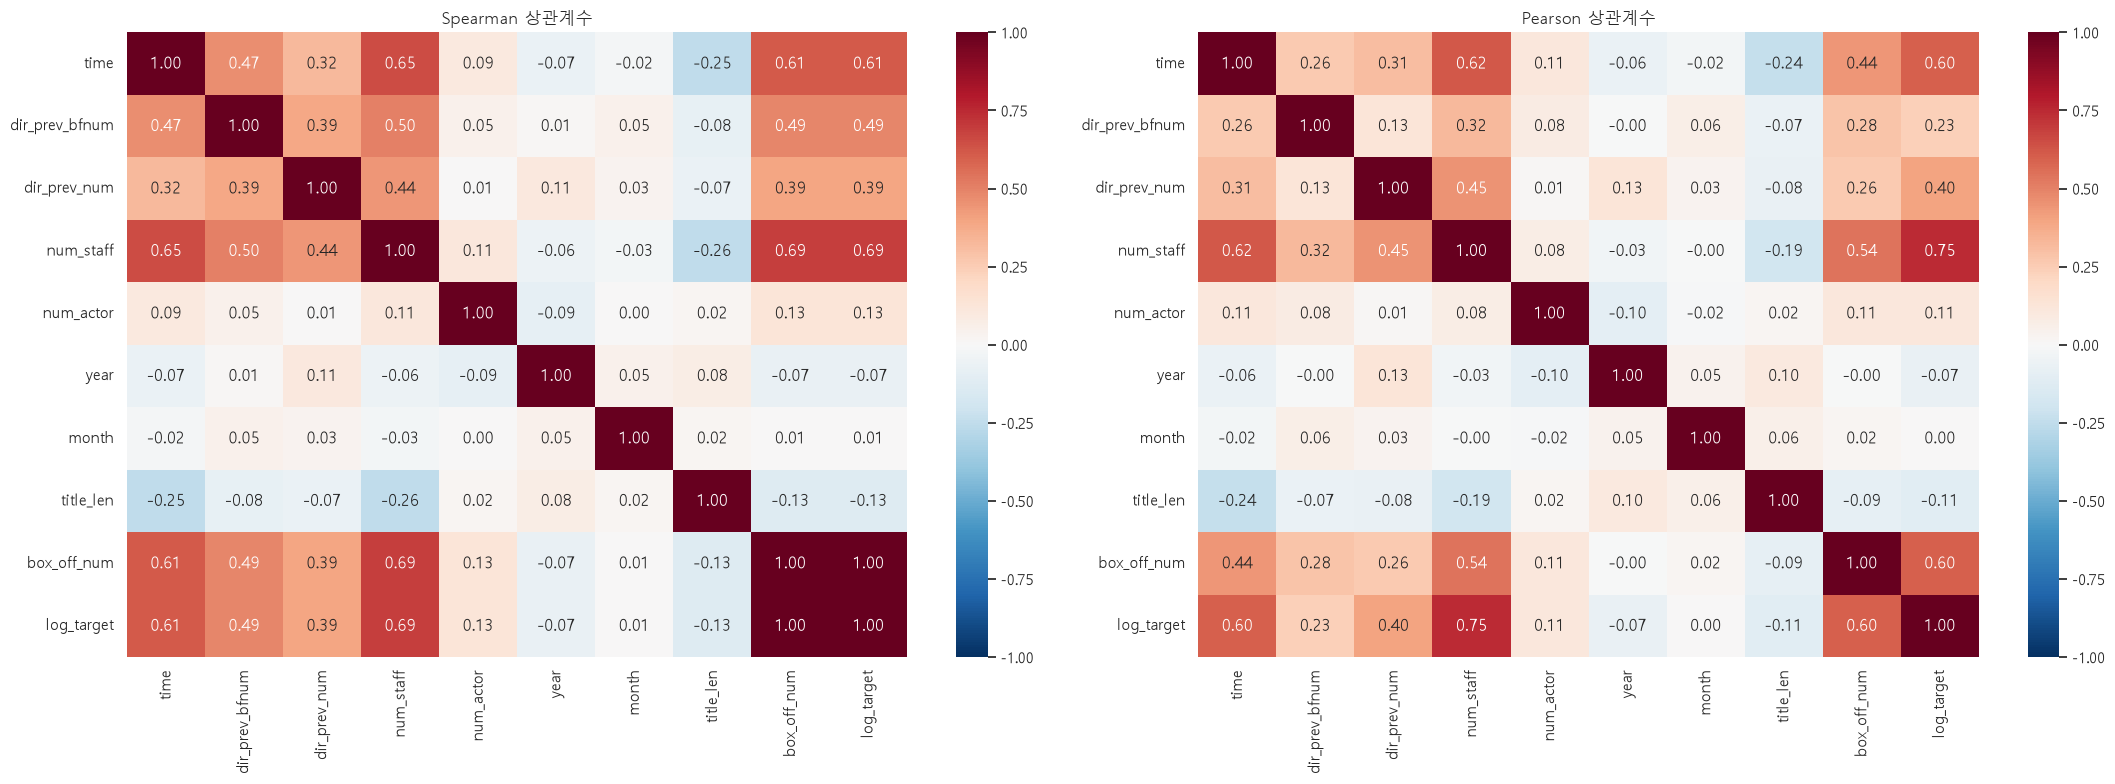

log 관객수와의 Spearman 상관 (절댓값 순)


,spearman
num_staff,0.694839
time,0.609441
dir_prev_bfnum,0.486496
dir_prev_num,0.394862
title_len,-0.131516
num_actor,0.126874
year,-0.072964
month,0.005435


In [35]:
num_feats = ['time', 'dir_prev_bfnum', 'dir_prev_num', 'num_staff', 'num_actor', 'year', 'month', 'title_len', TARGET, 'log_target']
fig, ax = plt.subplots(1, 2, figsize=(22, 8))
sns.heatmap(train[num_feats].corr(method='spearman'), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title('Spearman 상관계수')
sns.heatmap(train[num_feats].corr(method='pearson'), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title('Pearson 상관계수')
plt.tight_layout(); plt.show()

print('log 관객수와의 Spearman 상관 (절댓값 순)')
display(train[num_feats].corr(method='spearman')['log_target'].drop(['log_target', TARGET])
        .sort_values(key=abs, ascending=False).to_frame('spearman'))

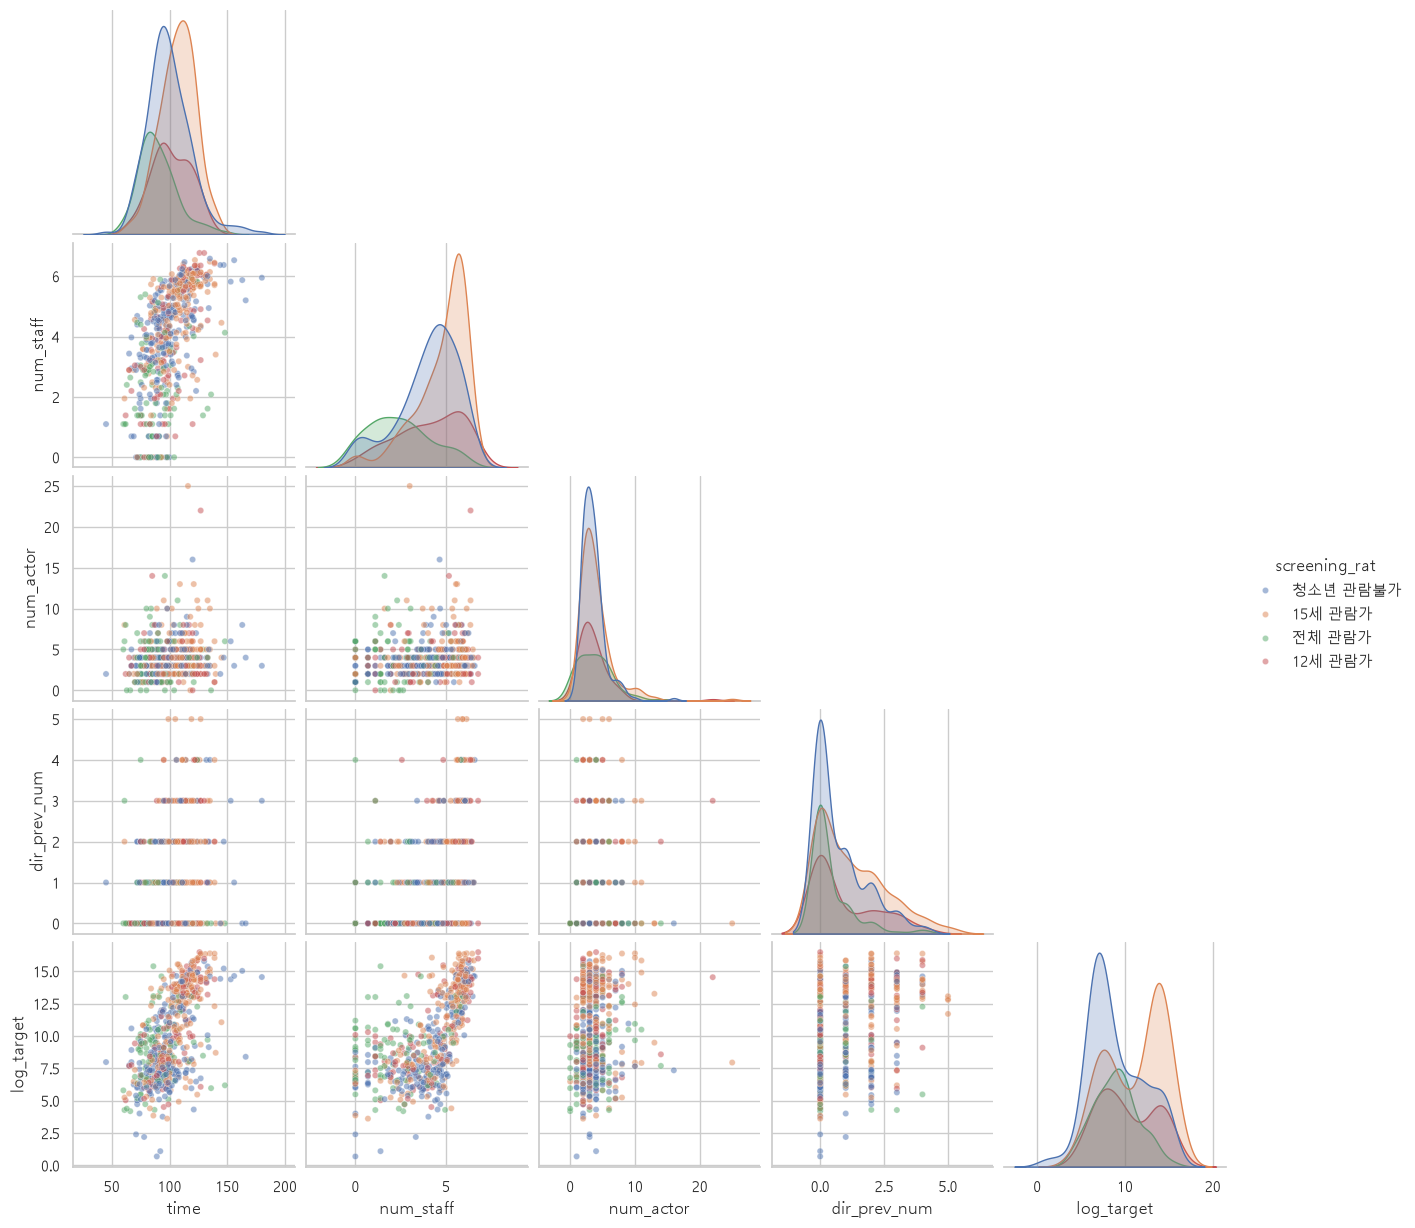

In [36]:
pp = train[['time', 'num_staff', 'num_actor', 'dir_prev_num', 'log_target', 'screening_rat']].copy()
pp['num_staff'] = np.log1p(pp['num_staff'])
sns.pairplot(pp, hue='screening_rat', corner=True, plot_kws={'alpha': .5, 's': 20})
plt.show()

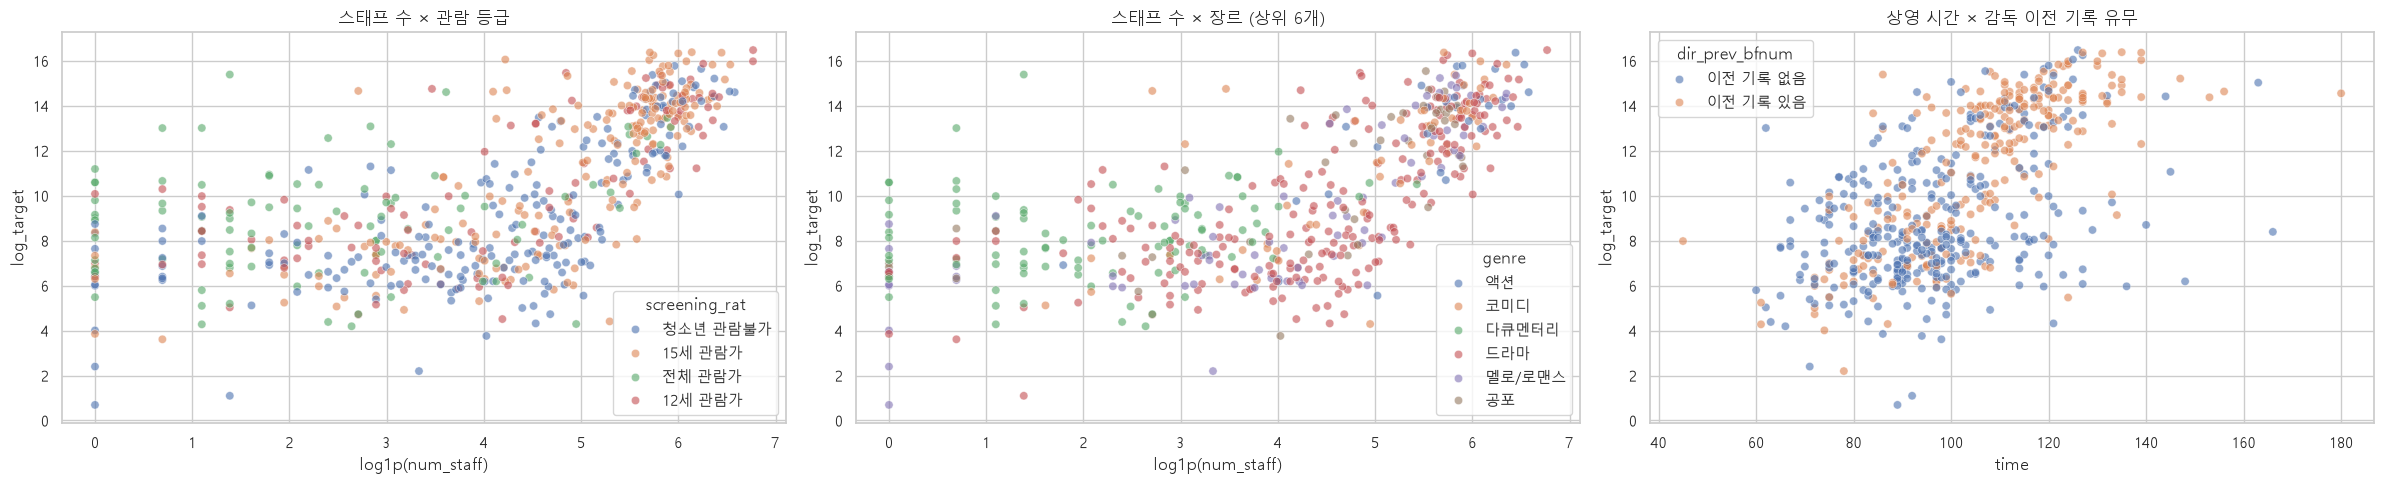

In [37]:
# 핵심 수치형 변수 × 범주형 변수: 관계가 범주마다 다른지 (상호작용 → 파생변수 아이디어)
fig, ax = plt.subplots(1, 3, figsize=(24, 5))
sns.scatterplot(data=train, x=np.log1p(train['num_staff']), y='log_target', hue='screening_rat', alpha=.6, ax=ax[0])
ax[0].set_xlabel('log1p(num_staff)'); ax[0].set_title('스태프 수 × 관람 등급')
top_genre = train['genre'].value_counts().index[:6]
sub = train[train['genre'].isin(top_genre)]
sns.scatterplot(data=sub, x=np.log1p(sub['num_staff']), y='log_target', hue='genre', alpha=.6, ax=ax[1])
ax[1].set_xlabel('log1p(num_staff)'); ax[1].set_title('스태프 수 × 장르 (상위 6개)')
sns.scatterplot(data=train, x='time', y='log_target', hue=train['dir_prev_bfnum'].isna().map({True: '이전 기록 없음', False: '이전 기록 있음'}), alpha=.6, ax=ax[2])
ax[2].set_title('상영 시간 × 감독 이전 기록 유무')
plt.tight_layout(); plt.show()

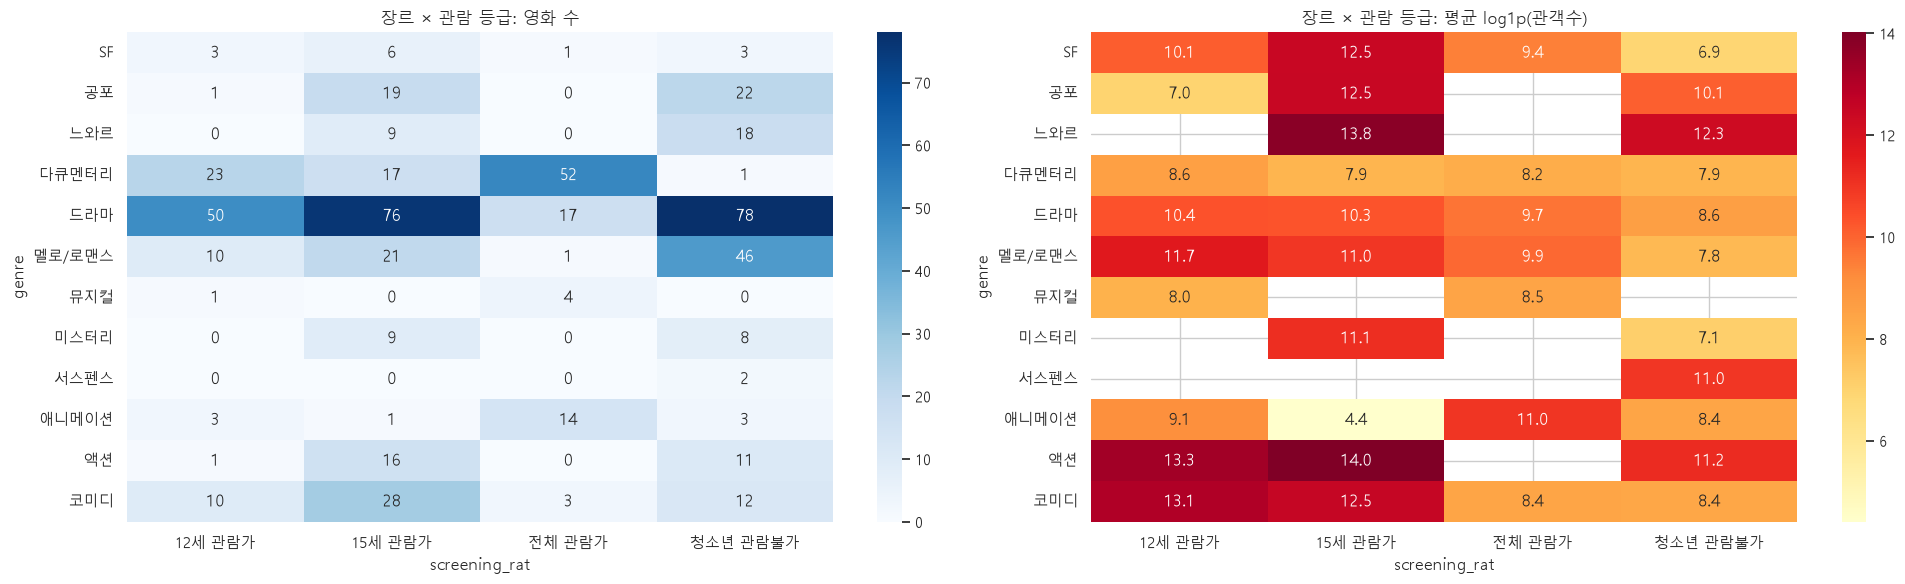

In [38]:
fig, ax = plt.subplots(1, 2, figsize=(20, 6))
sns.heatmap(pd.crosstab(train['genre'], train['screening_rat']), annot=True, fmt='d', cmap='Blues', ax=ax[0])
ax[0].set_title('장르 × 관람 등급: 영화 수')
sns.heatmap(train.pivot_table(index='genre', columns='screening_rat', values='log_target', aggfunc='mean'),
            annot=True, fmt='.1f', cmap='YlOrRd', ax=ax[1])
ax[1].set_title('장르 × 관람 등급: 평균 log1p(관객수)')
plt.tight_layout(); plt.show()

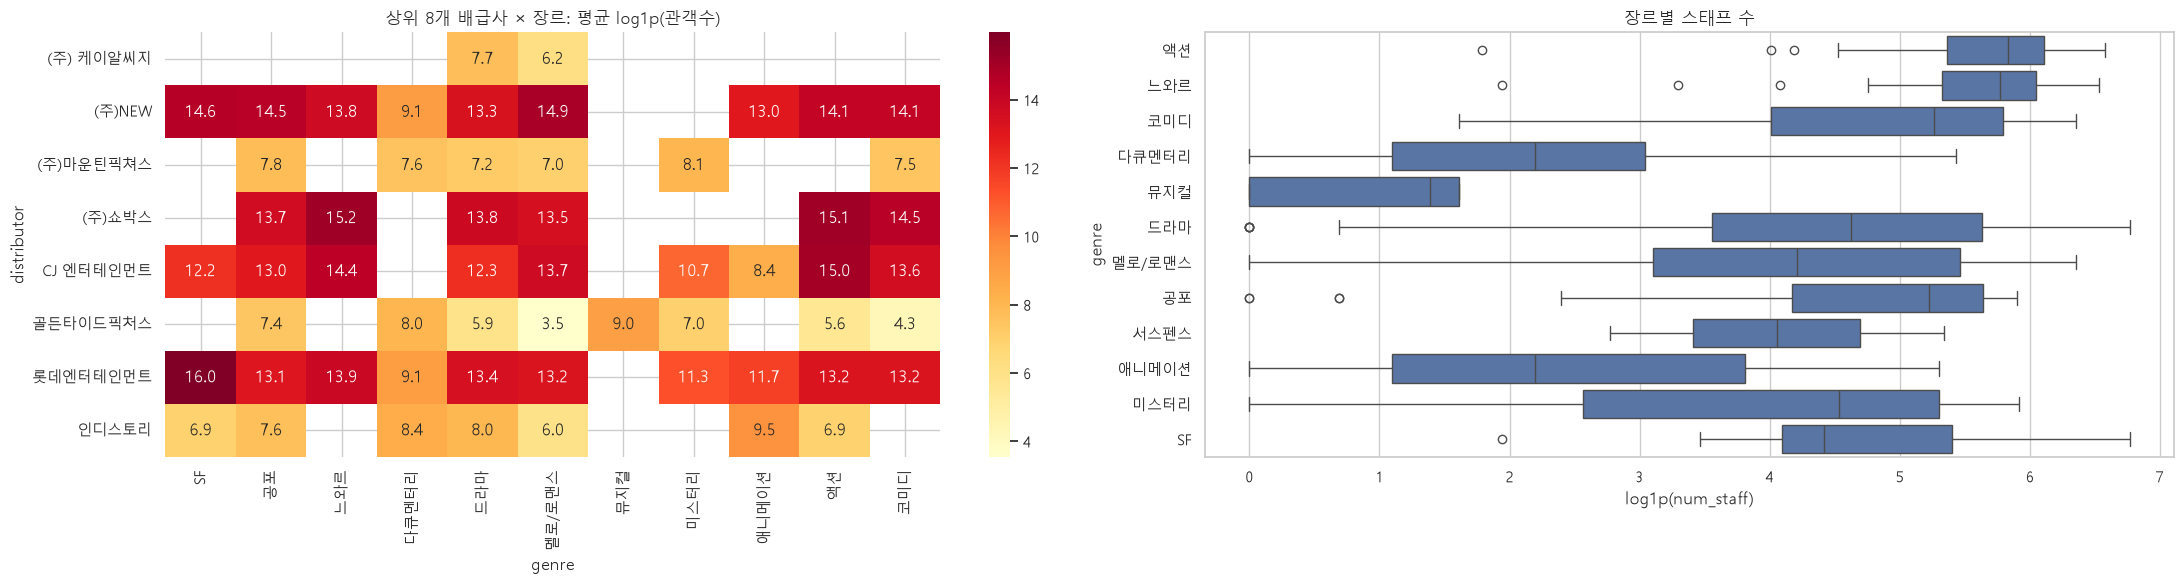

In [39]:
top_dist = train['distributor'].value_counts().index[:8]
sub = train[train['distributor'].isin(top_dist)]
fig, ax = plt.subplots(1, 2, figsize=(22, 6))
sns.heatmap(sub.pivot_table(index='distributor', columns='genre', values='log_target', aggfunc='mean'),
            annot=True, fmt='.1f', cmap='YlOrRd', ax=ax[0])
ax[0].set_title('상위 8개 배급사 × 장르: 평균 log1p(관객수)')
sns.boxplot(data=train, y='genre', x=np.log1p(train['num_staff']), ax=ax[1])
ax[1].set_xlabel('log1p(num_staff)'); ax[1].set_title('장르별 스태프 수')
plt.tight_layout(); plt.show()

## 9. train vs test 분포 비교
분포가 다르면 CV 점수와 리더보드 점수가 어긋날 수 있음.

In [40]:
rows = []
for col in ['time', 'dir_prev_bfnum', 'dir_prev_num', 'num_staff', 'num_actor', 'year', 'month', 'title_len']:
    ks = stats.ks_2samp(train[col].dropna(), test[col].dropna())
    rows.append({'변수': col, 'train 평균': train[col].mean(), 'test 평균': test[col].mean(),
                 'KS 통계량': ks.statistic, 'p-value': ks.pvalue})
display(pd.DataFrame(rows).style.format({'train 평균': '{:,.1f}', 'test 평균': '{:,.1f}', 'KS 통계량': '{:.3f}', 'p-value': '{:.3f}'}))
print('p-value가 0.05보다 작으면 train과 test 분포가 다르다고 볼 수 있음')

,변수,train 평균,test 평균,KS 통계량,p-value
0,time,100.9,109.8,0.080,0.201
1,dir_prev_bfnum,"1,050,442.9","891,669.5",0.090,0.528
2,dir_prev_num,0.9,0.9,0.019,1.000
3,num_staff,151.1,159.3,0.058,0.571
4,num_actor,3.7,3.5,0.053,0.690
5,year,"2,012.7","2,012.8",0.010,1.000
6,month,7.0,6.8,0.069,0.365
7,title_len,6.7,6.4,0.045,0.862


p-value가 0.05보다 작으면 train과 test 분포가 다르다고 볼 수 있음


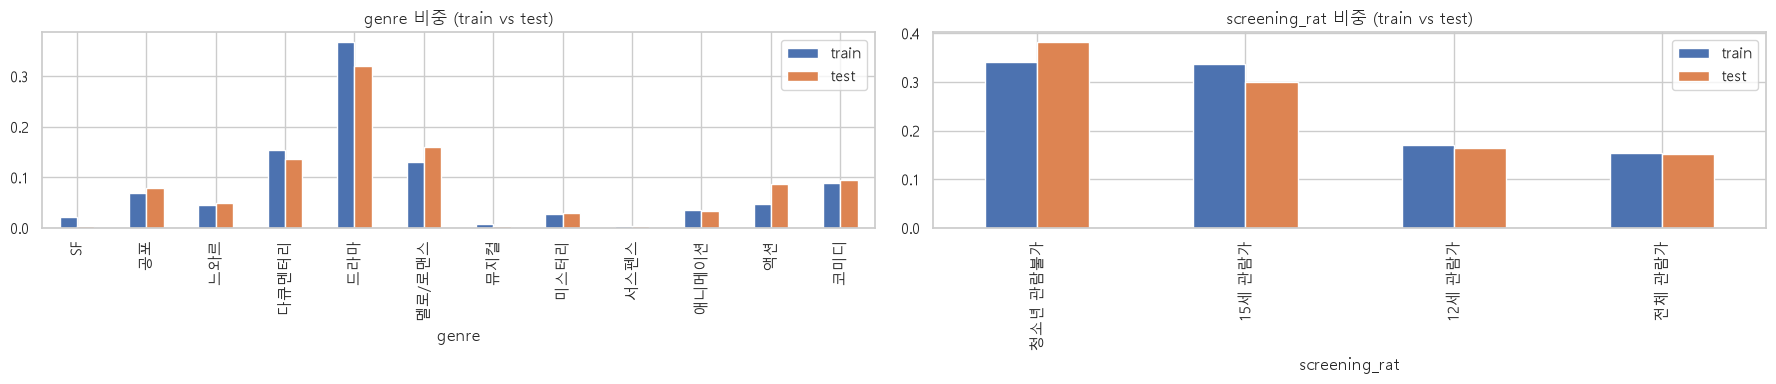

In [41]:
fig, ax = plt.subplots(1, 2, figsize=(18, 4))
for i, col in enumerate(['genre', 'screening_rat']):
    pd.DataFrame({'train': train[col].value_counts(normalize=True),
                  'test': test[col].value_counts(normalize=True)}).plot.bar(ax=ax[i], title=f'{col} 비중 (train vs test)')
plt.tight_layout(); plt.show()

## 10. 시사점 정리

위 결과를 보고 직접 채우기. 각 항목은 **02 TabPFN 베이스라인과 같은 CV로 점수가 좋아지는지** 확인해서 채택 여부 결정.

| # | 관찰 | 전처리 · 파생변수 아이디어 | 결과 (CV RMSE) |
| --- | --- | --- | --- |
| 1 | 타깃이 심하게 치우침, 상위 몇 편이 RMSE 대부분 | 로그 타깃 vs 원본 타깃 비교 |  |
| 2 | `dir_prev_bfnum` 결측 = 이전 작품 없음? | 결측 플래그 + 0으로 채우기 (지금은 컬럼 삭제 중) |  |
| 3 | 수치형 변수 치우침 (`num_staff` 등) | log1p 변환 |  |
| 4 | 배급사 표기 중복 · 편수 적은 배급사 많음 | 이름 정규화, 편수 기반 묶기 / 타깃 인코딩 |  |
| 5 | 개봉 연·월·요일 효과 | 요일 · 분기 · 성수기(여름/겨울) 플래그 |  |
| 6 | 변수 간 상호작용 (스태프 수 × 등급/장르) | 곱 · 비율 파생변수 |  |
| 6-1 | 관람 등급별 흥행률 차이 (5-2-1) | 15세 플래그 · 등급×스태프 상호작용 · 등급×장르 조합 |  |
| 7 | 제목 · 감독 정보 | 속편 플래그, 감독 출현 횟수 |  |
| 8 | train/test 분포 차이 | CV 결과와 리더보드 차이 해석에 참고 |  |